In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import pickle
import aux_functions as aux
importlib.reload(aux)

<module 'aux_functions' from '/media/kaori/PortableSSD/vispred/aux_functions.py'>

In [ ]:
MONKEY = 'M08'
# SESSION = 'm08cat252'
SESSION = 'm08cat255'
STR_DETAILS = f'Session {SESSION}'

In [4]:
with open(f"session_data/{SESSION}.pkl", "rb") as file:
    df_session= pickle.load(file)

df_session = df_session[df_session['RF_type']=='Focal Foveal']
df_session = df_session[df_session['brain_area']=='V4']
df_session.index = range(len(df_session.index))
STR_DETAILS += ' Foveal V4'

df_session

,start,search,mapRF,grid_coord,depth,brain_area,sample,array,prefer,SI,RFin,RFout,RF_type,session,neuron_id,coreRFin,
0,1982,m08cat252spk098a,m08det251spk098a,+3-3,916,V4,0.0,NaN,face,0.170110,NaN,NaN,Focal Foveal,m08cat252,spk098a,NaN,NaN
1,1983,m08cat252spk098b,m08det251spk098b,+3-3,916,V4,0.0,NaN,face,0.167200,NaN,NaN,Focal Foveal,m08cat252,spk098b,NaN,NaN
2,1984,m08cat252spk098z,m08det251spk098z,+3-3,916,V4,0.0,NaN,NaN,0.043894,NaN,NaN,Focal Foveal,m08cat252,spk098z,NaN,NaN
3,1987,m08cat252spk100a,m08det251spk100a,+3-3,926,V4,0.0,NaN,face,0.131520,NaN,NaN,Focal Foveal,m08cat252,spk100a,NaN,NaN
4,1988,m08cat252spk100b,m08det251spk100b,+3-3,926,V4,0.0,NaN,face,0.190290,NaN,NaN,Focal Foveal,m08cat252,spk100b,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2050,m08cat252spk127a,m08det251spk127a,+3-3,906,V4,0.0,NaN,face,0.243220,NaN,NaN,Focal Foveal,m08cat252,spk127a,NaN,NaN
62,2051,m08cat252spk127b,m08det251spk127b,+3-3,906,V4,0.0,NaN,face,0.401340,NaN,NaN,Focal Foveal,m08cat252,spk127b,NaN,NaN
63,2052,m08cat252spk127z,m08det251spk127z,+3-3,906,V4,0.0,NaN,face,0.102320,NaN,NaN,Focal Foveal,m08cat252,spk127z,NaN,NaN
64,2053,m08cat252spk128a,m08det251spk128a,+3-3,1066,V4,0.0,NaN,face,0.236100,NaN,NaN,Focal Foveal,m08cat252,spk128a,NaN,NaN


#### Dataframe com uma linha a cada (trial,sacada,neuronio)

In [5]:
path_destiny = f'dados/{MONKEY}_neurons/neurons sorted' # linux
list_neuron_ids = df_session['search']
list_prefered_cat = df_session['prefer']
list_brain_area = df_session['brain_area']

df_trials, dicio_firings = aux.get_df_trials_all_saccs_foveal(list_neuron_ids, path_destiny, list_prefered_cat, list_brain_area)
df_trials

,neuron,prefered,brain_area,trial_num,cue_id,cue_cath,pre_sacc_time,FP_on,fix_FP,cue_on,...,sacc_num,trial+sacc,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior
0,m08cat252spk098a,face,V4,1,3004.0,face,0.136900,3.152367,4.781567,5.208733,...,0,1_0,8.0,1027.0,flower,6.927533,6.941867,7.146267,0.0,fix_point
1,m08cat252spk098a,face,V4,1,3004.0,face,0.136900,3.152367,4.781567,5.208733,...,1,1_1,19.0,2001.0,house,7.146267,7.149000,7.554400,8.0,flower
2,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,0,4_0,8.0,2021.0,house,14.604467,14.606267,14.748767,0.0,fix_point
3,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,1,4_1,2.0,3013.0,face,14.748767,14.750900,15.552967,8.0,house
4,m08cat252spk098a,face,V4,6,3012.0,face,0.170467,17.427567,17.604033,18.011200,...,0,6_0,19.0,3007.0,face,19.535167,19.547400,20.350700,0.0,fix_point
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328873,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,4,2638_4,3.0,3006.0,face,14755.062367,14755.064133,14755.070100,2.0,face
328874,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,5,2638_5,12.0,2055.0,house,14755.070100,14755.071933,14755.283267,3.0,face
328875,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,6,2638_6,3.0,3006.0,face,14755.283267,14755.285100,14755.293733,12.0,house
328876,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,7,2638_7,4.0,1012.0,flower,14755.293733,14755.296600,14755.447033,3.0,face


#### Gerar dataframe de Y+Bins que usaremos nos modelos de ML

In [6]:
start_time = -300
end_time = 300
bin_width = 50
step = 10

In [7]:
t_ends = np.arange(start_time + bin_width, end_time + step, step)
df_run_model = aux.get_df_run_ml(df_trials, start_time, end_time, bin_width, step, dicio_firings)
df_run_model

,Y_cat,Y_equality,Y_is_cue,cat_cue,cat_anterior,transition,m08cat252spk098a_Bin0,m08cat252spk098a_Bin1,m08cat252spk098a_Bin2,m08cat252spk098a_Bin3,...,m08cat252spk128z_Bin46,m08cat252spk128z_Bin47,m08cat252spk128z_Bin48,m08cat252spk128z_Bin49,m08cat252spk128z_Bin50,m08cat252spk128z_Bin51,m08cat252spk128z_Bin52,m08cat252spk128z_Bin53,m08cat252spk128z_Bin54,m08cat252spk128z_Bin55
0,flower,0,0,face,fix_point,fix_point-flower,80.0,80.0,60.0,60.0,...,60.0,80.0,80.0,40.0,40.0,60.0,60.0,80.0,80.0,80.0
1,house,0,0,face,flower,flower-house,40.0,40.0,40.0,20.0,...,0.0,20.0,20.0,60.0,80.0,80.0,100.0,120.0,80.0,60.0
2,house,0,0,face,fix_point,fix_point-house,40.0,20.0,0.0,20.0,...,40.0,20.0,20.0,0.0,0.0,0.0,0.0,20.0,40.0,60.0
3,face,0,1,face,house,house-face,20.0,40.0,40.0,20.0,...,80.0,60.0,60.0,40.0,40.0,20.0,20.0,20.0,0.0,20.0
4,face,0,1,face,fix_point,fix_point-face,0.0,0.0,0.0,0.0,...,80.0,80.0,60.0,40.0,80.0,80.0,60.0,40.0,60.0,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4978,face,1,0,house,face,face-face,100.0,140.0,160.0,140.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
4979,house,0,1,house,face,face-house,140.0,160.0,140.0,160.0,...,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4980,face,0,0,house,house,house-face,100.0,100.0,80.0,80.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
4981,flower,0,0,house,face,face-flower,80.0,80.0,80.0,80.0,...,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0


#### rodar decoding

In [8]:
# decoding_type = 'CATEGORY'
# decoding_type = 'CUE_CATEGORY'
# decoding_type = 'IS_CUE'
# decoding_type = 'CHANGE_OF_CATEGORY'

In [9]:
res_category = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model,
    start_time=start_time,     
    decoding_type='CATEGORY',
    bin_width=bin_width,        
    step=step,             
    # window_size_bins=4   
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 56 janelas, 56 bins totais)...
Bins selecionados para Tuning: [25]
--- Processando Fold 1/5 --- 16:48:23
--- Processando Fold 2/5 --- 16:48:49
--- Processando Fold 3/5 --- 16:49:19
--- Processando Fold 4/5 --- 16:49:51
--- Processando Fold 5/5 --- 16:50:19


In [10]:
import seaborn as sns
def plot_decoding(results):
    plt.figure(figsize=(10, 5))
    plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Chegada da Sacada (t=0)')
    plt.axhline(y=results['chance_level'], color='black', linestyle=':', label=f"Chance Level ({results['chance_level']:.1f}%)")
    plt.plot(results['window_ends'], results['mean_acc'], color='dodgerblue', linewidth=2.5, marker='o', label='SVM Linear')
    plt.title(f'{STR_DETAILS} | Decodificabilidade (1 Bin de 50ms)', fontsize=14)
    plt.ylabel('Acurácia (%)', fontsize=12)
    plt.ylabel('Média Geométrica da Sensibilidade (%)', fontsize=12)
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


def plot_decoding_by_class(results, class_name, classes, titulo_plot, txt_add_title='', chance_level=25):
    tempos = results['window_ends']
    plt.figure(figsize=(10,6))
    for c in classes:
        acc_temporal = results[class_name][c]
        plt.plot(tempos, acc_temporal, marker='o', label=c)
    plt.axvline(x=0, color='red', linestyle='--', label='Chegada da Sacada')
    plt.axhline(y=chance_level, color='black', linestyle='--', label='Chance level')
    plt.ylabel('Acurácia (%)')
    plt.xlabel('Tempo em relação à fixação (ms)')
    plt.legend()
    plt.title(f'{STR_DETAILS} {txt_add_title} | {titulo_plot}')
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_temporal_confusion_matrix(result_decoding, target_time_ms,str_bins=''):
    """
    Plota a Matriz de Confusão para o instante de tempo (causal) mais próximo do solicitado.
    
    Parâmetros:
    -----------
    result_decoding : dict (retorno da função run_temporal_decoding)
    target_time_ms : int ou float (tempo em ms que você quer analisar, ex: 100)
    """
    
    # 1. Encontra o índice da janela temporal mais próxima do target_time_ms
    window_ends = result_decoding['window_ends']
    idx = np.argmin(np.abs(window_ends - target_time_ms))
    actual_time = window_ends[idx]
    
    # 2. Resgata a matriz e as classes exatas desse instante
    cm = result_decoding['mean_cms'][idx]
    classes = result_decoding['classes']
    
    # 3. Configura e plota o Heatmap
    plt.figure(figsize=(7, 6))
    
    # annot=True mostra os números, fmt='.1f' deixa 1 casa decimal, cmap é a paleta de cores
    sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=classes, yticklabels=classes,
                cbar_kws={'label': 'Acurácia (%)'},
                vmin=0, vmax=100)
    
    plt.title(f'{STR_DETAILS} | Matriz de Confusão aos {actual_time} ms | {str_bins} | Acurácia = {int(result_decoding["mean_acc"][list(result_decoding["window_ends"]).index(float(target_time_ms))])}%', fontsize=14, pad=15)
    # plt.title(f'{STR_DETAILS} | Matriz de Confusão (Fim da Janela: {actual_time} ms) (1 Bin de 50ms) | Acurácia = {int(result_decoding["mean_acc"][list(result_decoding["window_ends"]).index(float(target_time_ms))])}%', fontsize=14, pad=15)
    plt.ylabel('Classe Verdadeira', fontsize=12)
    plt.xlabel('Classe Prevista pelo Modelo', fontsize=12)
    
    # Rotaciona os rótulos para melhor leitura
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    
    plt.tight_layout()
    plt.show()

def plot_multiple_CM(res, list_target_times, str_bins=''):
    for target_time in list_target_times:
        plot_temporal_confusion_matrix(res, target_time_ms=target_time,str_bins=str_bins)



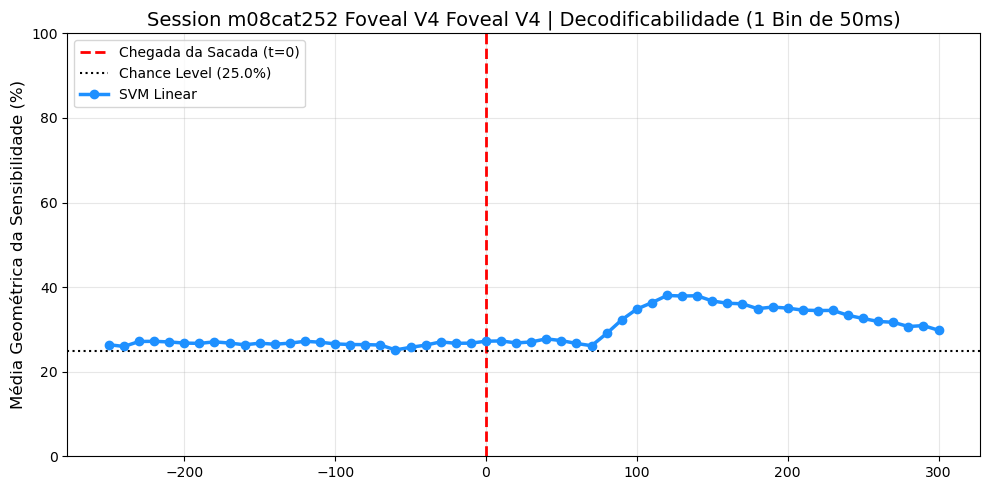

In [11]:
plot_decoding(res_category)

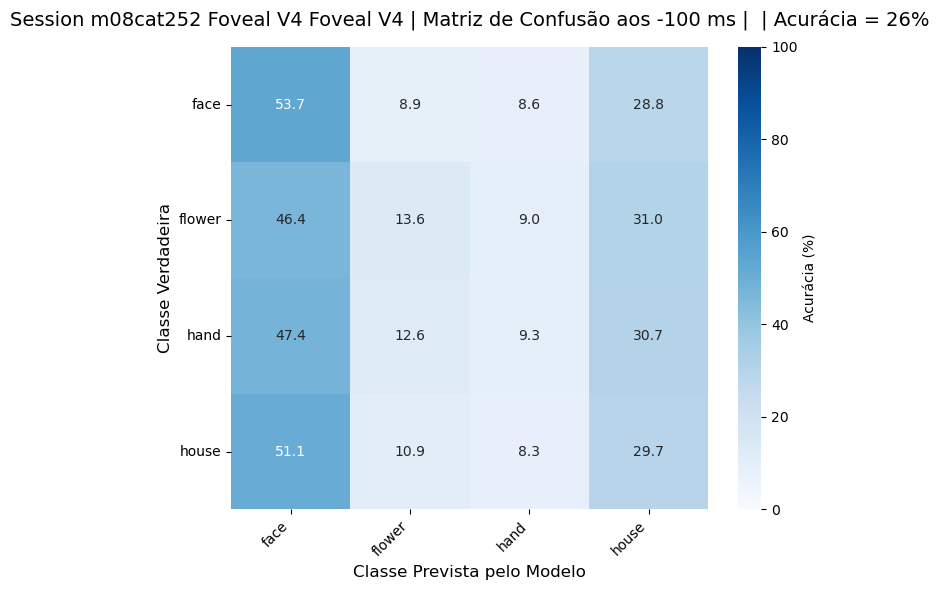

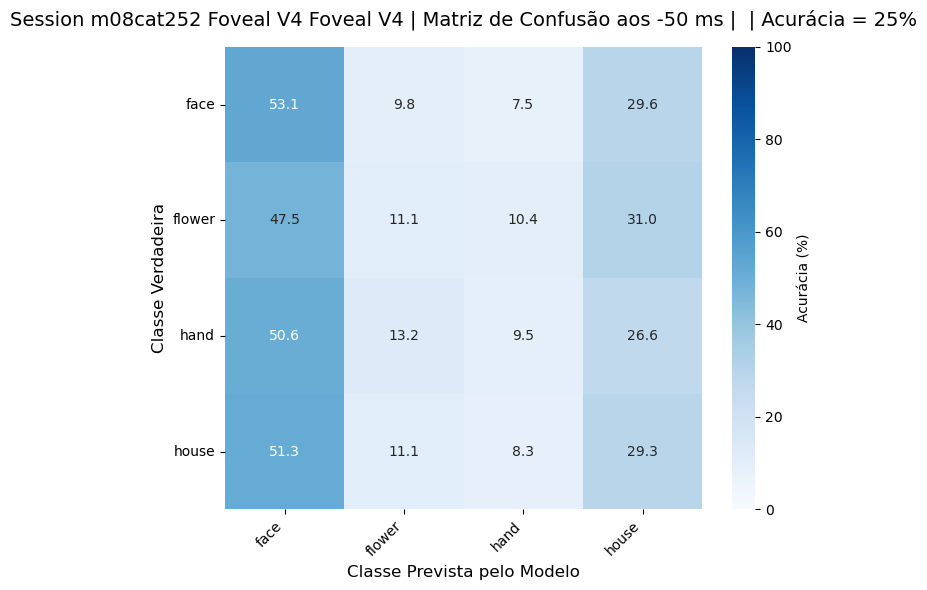

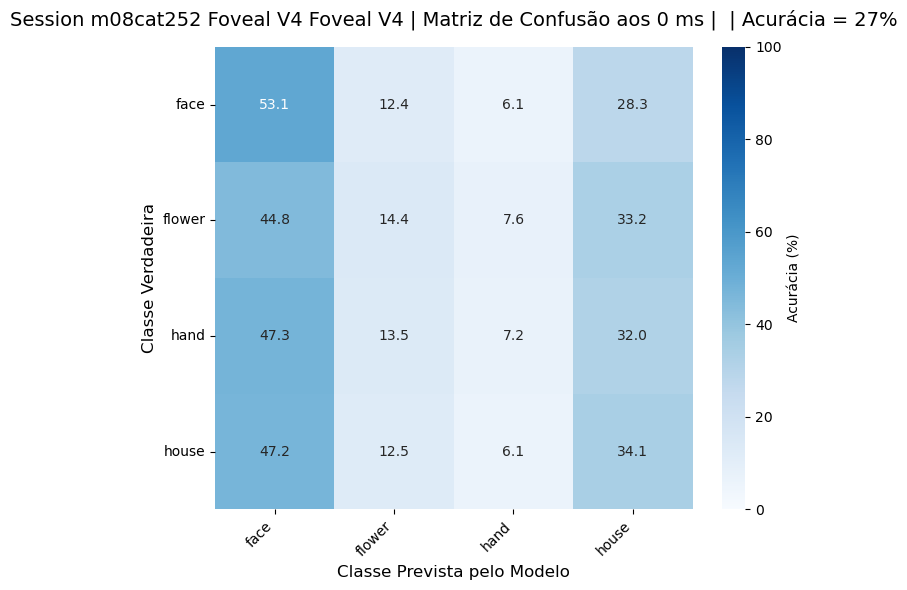

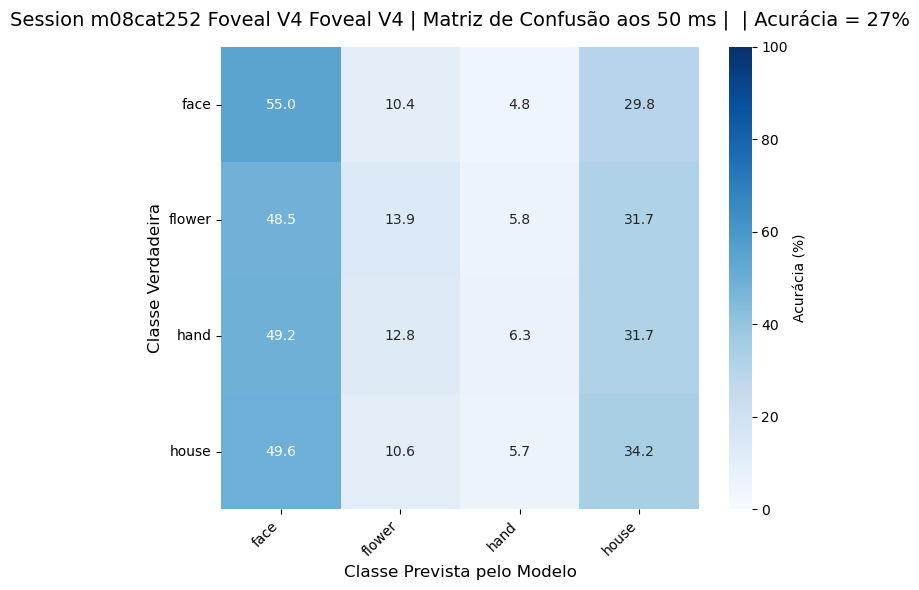

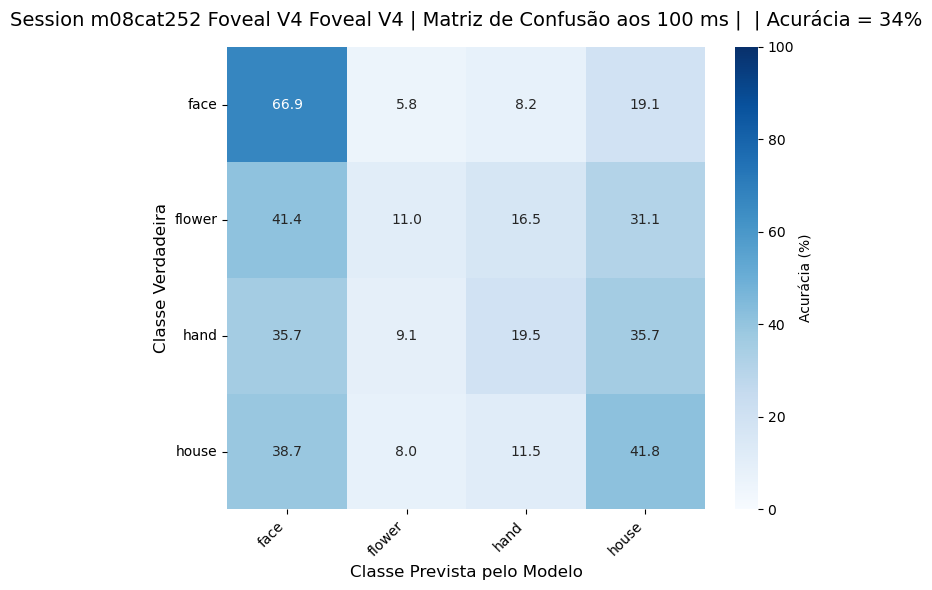

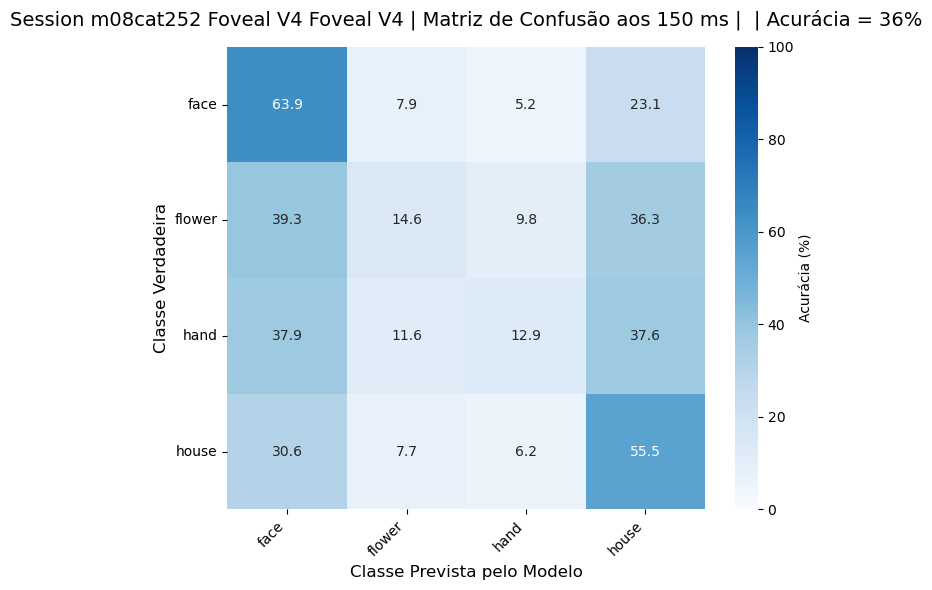

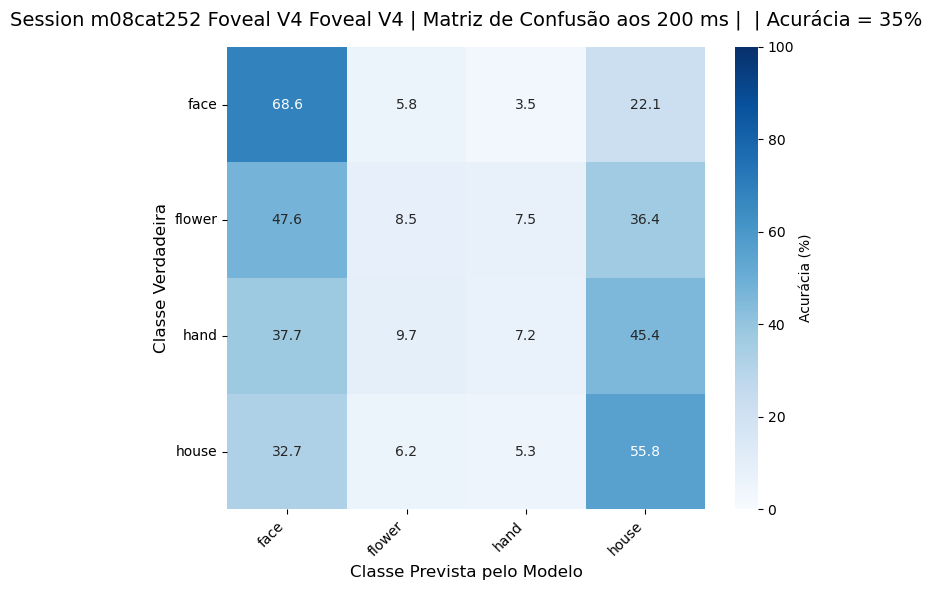

In [12]:
plot_multiple_CM(res_category,[-100,-50,0,50,100,150,200])

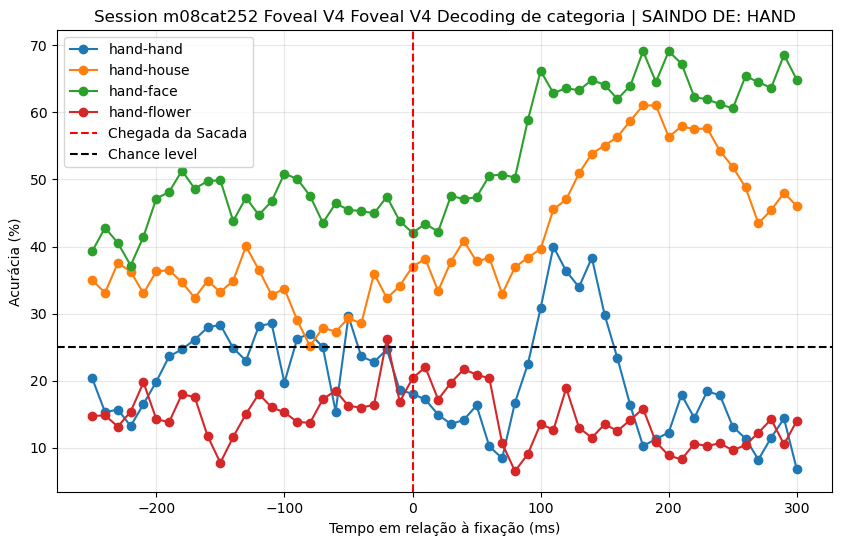

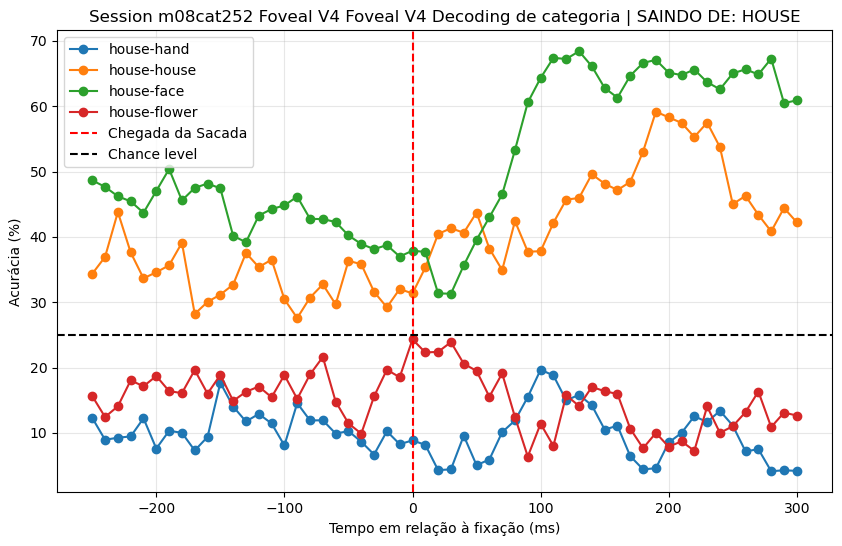

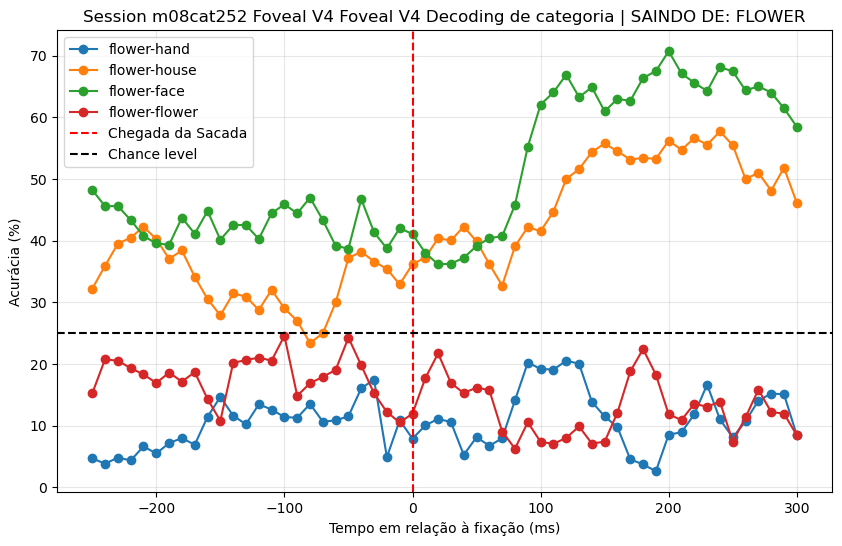

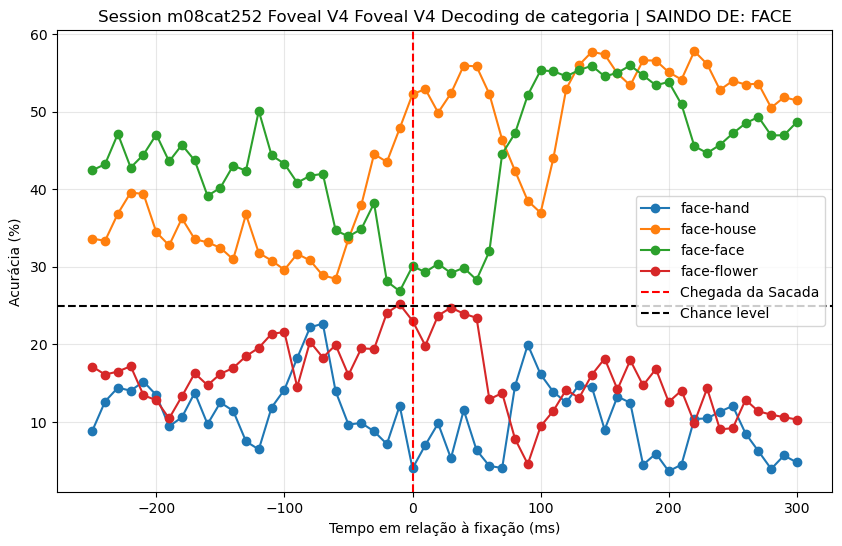

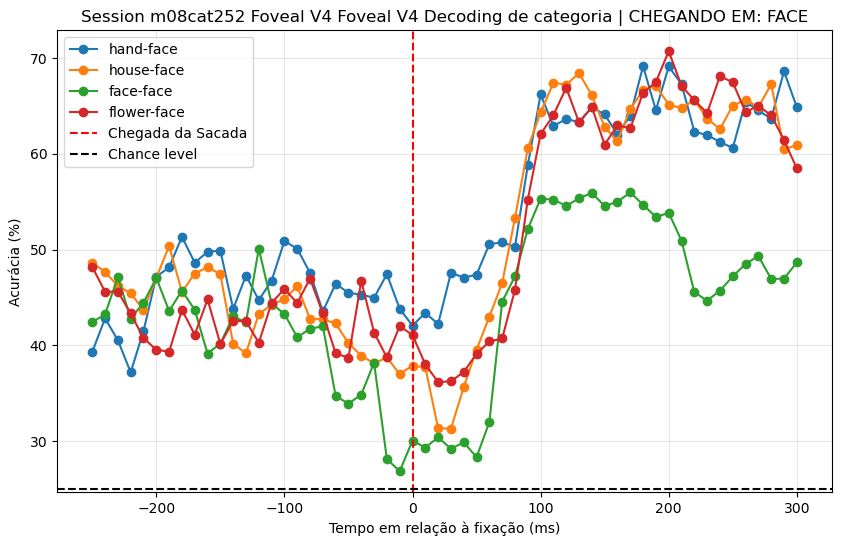

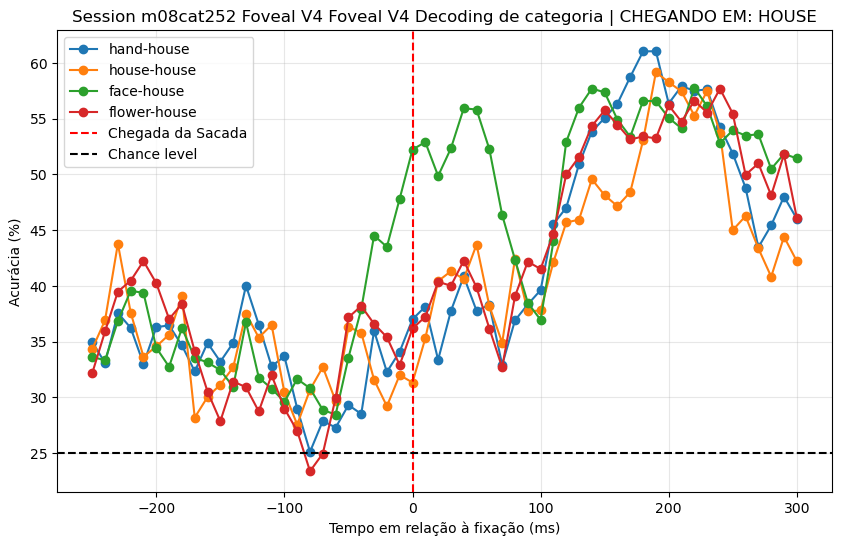

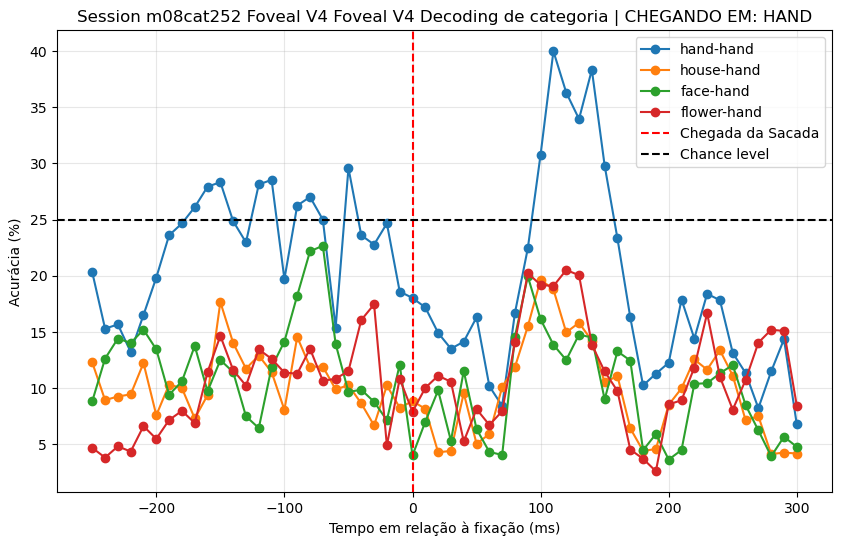

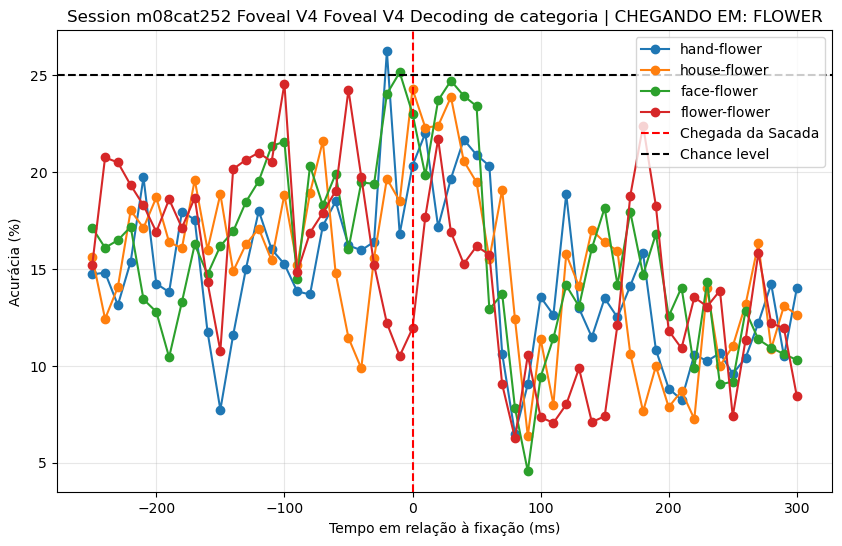

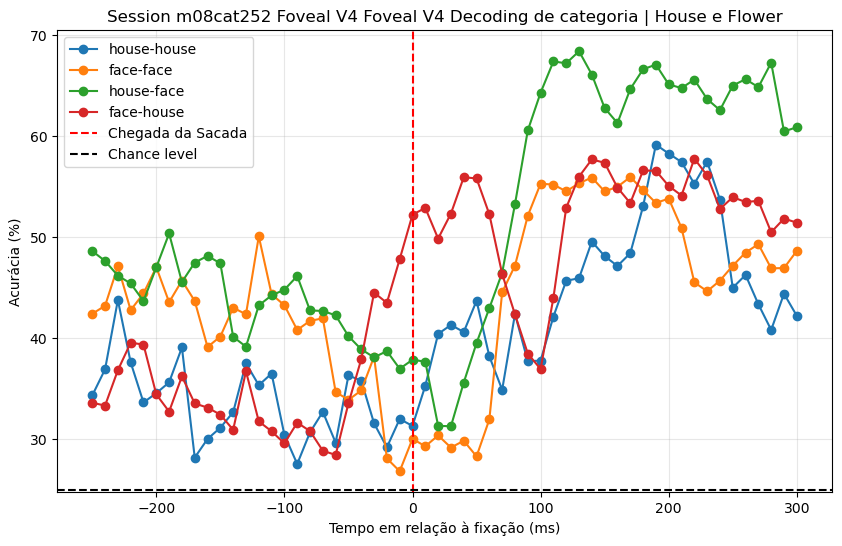

In [13]:
txt_add_title = 'Decoding de categoria'

classes_plotar = ['hand-hand','hand-house','hand-face','hand-flower']
titulo_plot = 'SAINDO DE: HAND'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['house-hand','house-house','house-face','house-flower']
titulo_plot = 'SAINDO DE: HOUSE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['flower-hand','flower-house','flower-face','flower-flower']
titulo_plot = 'SAINDO DE: FLOWER'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['face-hand','face-house','face-face','face-flower']
titulo_plot = 'SAINDO DE: FACE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['hand-face','house-face','face-face','flower-face']
titulo_plot = 'CHEGANDO EM: FACE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['hand-house','house-house','face-house','flower-house']
titulo_plot = 'CHEGANDO EM: HOUSE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['hand-hand','house-hand','face-hand','flower-hand']
titulo_plot = 'CHEGANDO EM: HAND'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['hand-flower','house-flower','face-flower','flower-flower']
titulo_plot = 'CHEGANDO EM: FLOWER'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = ['house-house','face-face', 'house-face','face-house']
titulo_plot = 'House e Flower'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title)



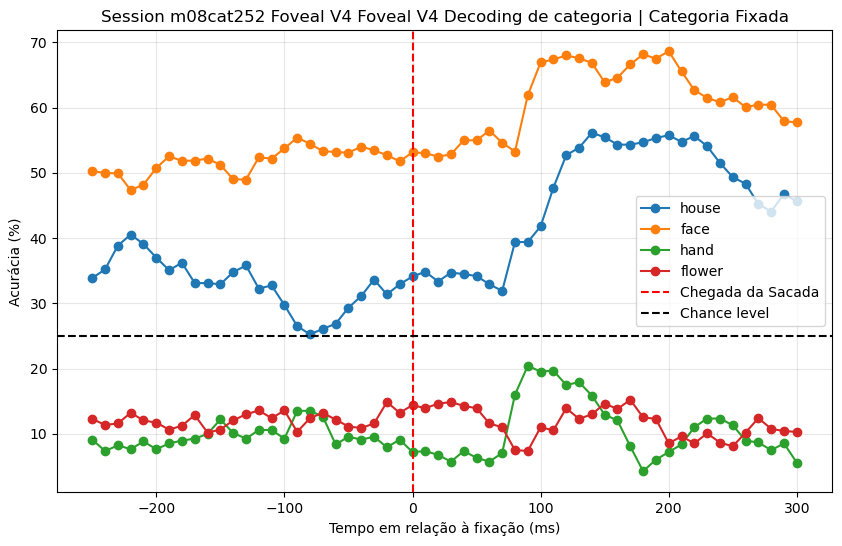

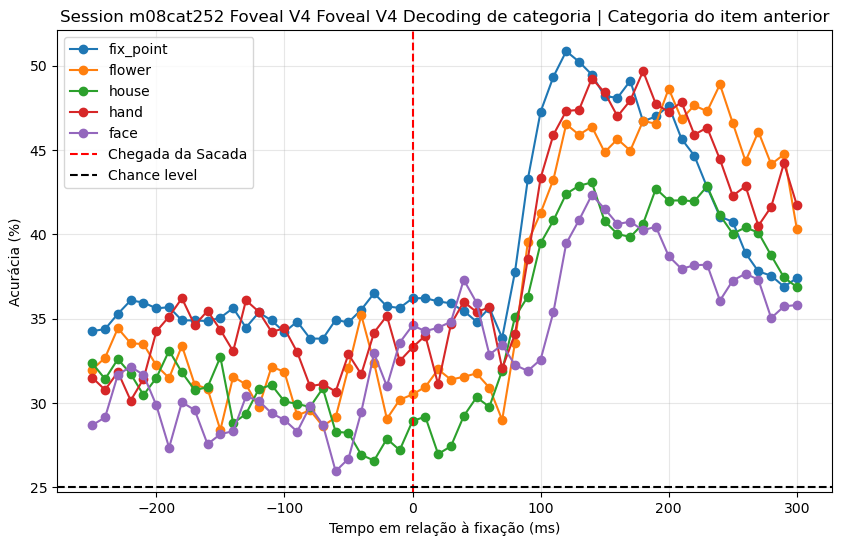

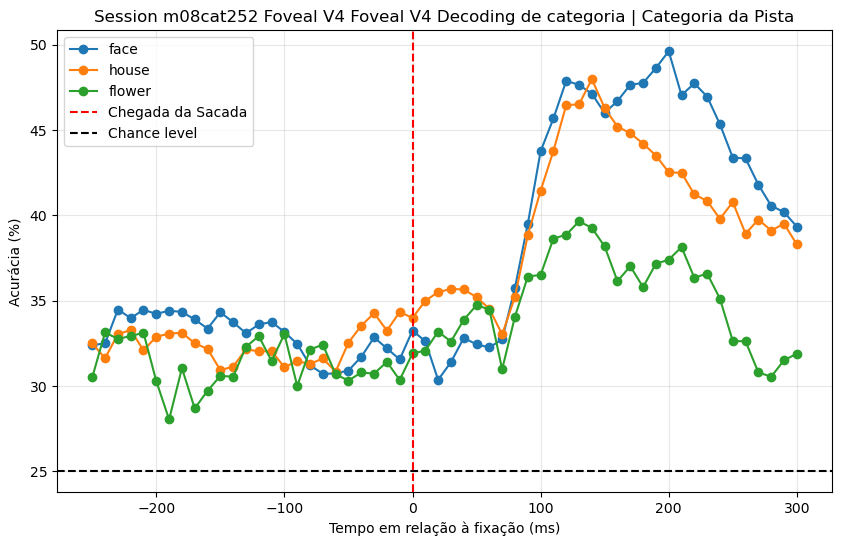

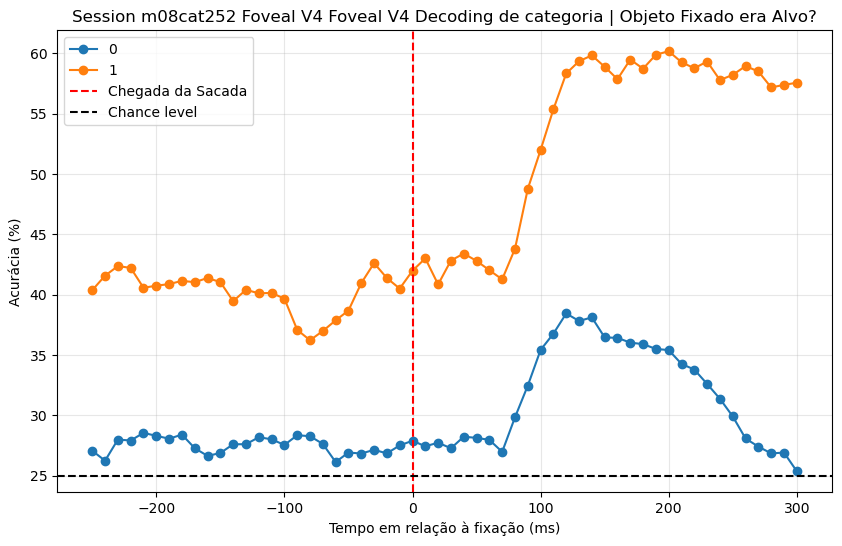

In [14]:
txt_add_title = 'Decoding de categoria'

classes_plotar = ['house','face','hand','flower']
titulo_plot = 'Categoria Fixada'
plot_decoding_by_class(res_category, 'mean_acc_cat_atual', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category['mean_acc_cat_anterior'].keys()
titulo_plot = 'Categoria do item anterior'
plot_decoding_by_class(res_category, 'mean_acc_cat_anterior', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category['mean_acc_cat_cue'].keys()
titulo_plot = 'Categoria da Pista'
plot_decoding_by_class(res_category, 'mean_acc_cat_cue', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category['mean_acc_is_cue'].keys()
titulo_plot = 'Objeto Fixado era Alvo?'
plot_decoding_by_class(res_category, 'mean_acc_is_cue', classes_plotar, titulo_plot, txt_add_title)


# Alternativas

## Somente primeiras sacadas

In [ ]:
df_trials2 = df_trials[df_trials['sacc_num']==0]
df_trials2

,neuron,prefered,brain_area,trial_num,cue_id,cue_cath,pre_sacc_time,FP_on,fix_FP,cue_on,...,sacc_num,trial+sacc,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior
0,m08cat252spk098a,face,V4,1,3004.0,face,0.136900,3.152367,4.781567,5.208733,...,0,1_0,8.0,1027.0,flower,6.927533,6.941867,7.146267,0.0,fix_point
2,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,0,4_0,8.0,2021.0,house,14.604467,14.606267,14.748767,0.0,fix_point
4,m08cat252spk098a,face,V4,6,3012.0,face,0.170467,17.427567,17.604033,18.011200,...,0,6_0,19.0,3007.0,face,19.535167,19.547400,20.350700,0.0,fix_point
5,m08cat252spk098a,face,V4,8,2053.0,house,0.150233,23.919500,24.430500,24.836400,...,0,8_0,6.0,4007.0,hand,26.784433,26.786367,26.789167,0.0,fix_point
9,m08cat252spk098a,face,V4,9,2006.0,house,0.135567,28.890800,29.073700,29.481433,...,0,9_0,8.0,1025.0,flower,31.032900,31.034767,31.155033,0.0,fix_point
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328854,m08cat252spk128z,NaN,V4,2601,2006.0,house,0.137567,14608.091067,14608.921067,14609.327233,...,0,2601_0,8.0,2019.0,house,14611.026633,14611.028933,14611.224900,0.0,fix_point
328860,m08cat252spk128z,NaN,V4,2603,3010.0,face,0.170600,14617.443533,14617.446133,14617.853633,...,0,2603_0,2.0,2017.0,house,14619.599800,14619.601733,14619.753267,0.0,fix_point
328862,m08cat252spk128z,NaN,V4,2604,2023.0,house,0.161367,14621.713600,14621.834833,14622.241600,...,0,2604_0,2.0,2024.0,house,14623.555133,14623.557067,14623.716900,0.0,fix_point
328865,m08cat252spk128z,NaN,V4,2605,3033.0,face,0.168967,14625.678133,14625.864367,14626.268700,...,0,2605_0,19.0,2019.0,house,14627.909267,14627.917067,14628.077200,0.0,fix_point


In [ ]:
df_run_model2 = aux.get_df_run_ml(df_trials2, start_time, end_time, bin_width, step, dicio_firings)
df_run_model2

,Y_cat,Y_equality,Y_is_cue,cat_cue,cat_anterior,transition,m08cat252spk098a_Bin0,m08cat252spk098a_Bin1,m08cat252spk098a_Bin2,m08cat252spk098a_Bin3,...,m08cat252spk128z_Bin2,m08cat252spk128z_Bin3,m08cat252spk128z_Bin4,m08cat252spk128z_Bin5,m08cat252spk128z_Bin6,m08cat252spk128z_Bin7,m08cat252spk128z_Bin8,m08cat252spk128z_Bin9,m08cat252spk128z_Bin10,m08cat252spk128z_Bin11
0,flower,0,0,face,fix_point,fix_point-flower,80.0,60.0,20.0,20.0,...,20.0,20.0,20.0,60.0,20.0,40.0,20.0,60.0,40.0,80.0
1,house,0,0,face,fix_point,fix_point-house,40.0,40.0,60.0,40.0,...,0.0,60.0,0.0,20.0,0.0,60.0,40.0,40.0,0.0,60.0
2,face,0,1,face,fix_point,fix_point-face,0.0,0.0,20.0,60.0,...,100.0,60.0,0.0,20.0,20.0,40.0,20.0,80.0,80.0,20.0
3,hand,0,0,house,fix_point,fix_point-hand,0.0,80.0,160.0,20.0,...,60.0,60.0,40.0,80.0,80.0,100.0,60.0,40.0,20.0,20.0
4,flower,0,0,house,fix_point,fix_point-flower,20.0,20.0,0.0,20.0,...,0.0,20.0,40.0,0.0,20.0,40.0,80.0,20.0,60.0,60.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1732,house,0,1,house,fix_point,fix_point-house,0.0,0.0,20.0,60.0,...,20.0,0.0,20.0,0.0,0.0,60.0,0.0,20.0,20.0,0.0
1733,house,0,0,face,fix_point,fix_point-house,0.0,0.0,0.0,20.0,...,20.0,40.0,0.0,20.0,0.0,0.0,0.0,20.0,20.0,40.0
1734,house,0,1,house,fix_point,fix_point-house,20.0,0.0,20.0,0.0,...,0.0,0.0,0.0,0.0,20.0,0.0,40.0,20.0,20.0,40.0
1735,house,0,0,face,fix_point,fix_point-house,100.0,60.0,0.0,0.0,...,20.0,0.0,40.0,0.0,0.0,40.0,60.0,0.0,20.0,20.0


In [ ]:
res_category2 = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model2,
    start_time=start_time,     
    decoding_type='CATEGORY',
    bin_width=bin_width,        
    step=step,             
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 12 janelas, 12 bins totais)...
Bins selecionados para Tuning: [5]
--- Processando Fold 1/5 --- 18:43:43
--- Processando Fold 2/5 --- 18:43:46
--- Processando Fold 3/5 --- 18:43:48
--- Processando Fold 4/5 --- 18:43:51
--- Processando Fold 5/5 --- 18:43:54


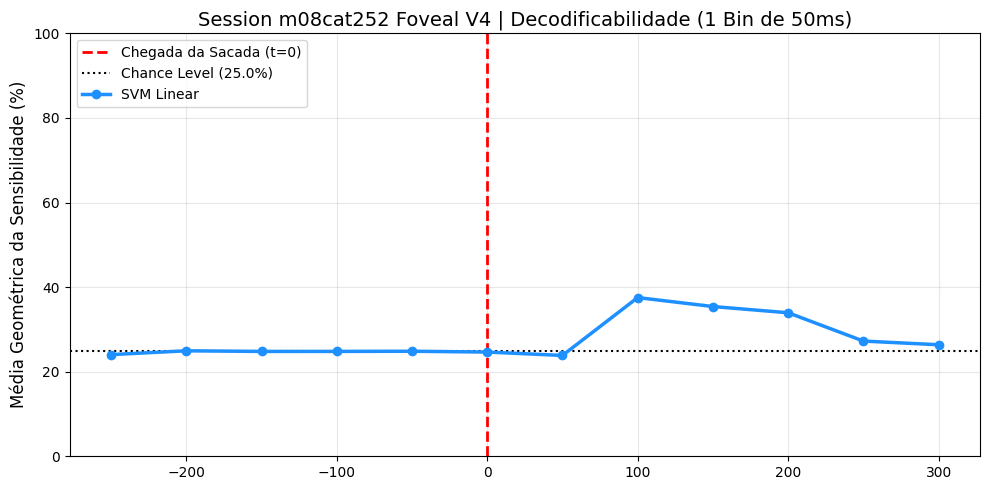

In [ ]:
plot_decoding(res_category2)

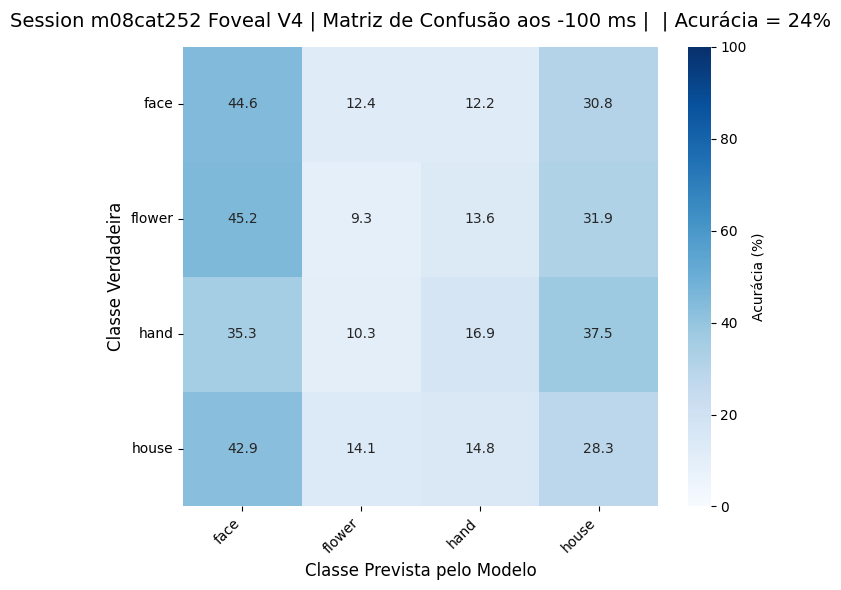

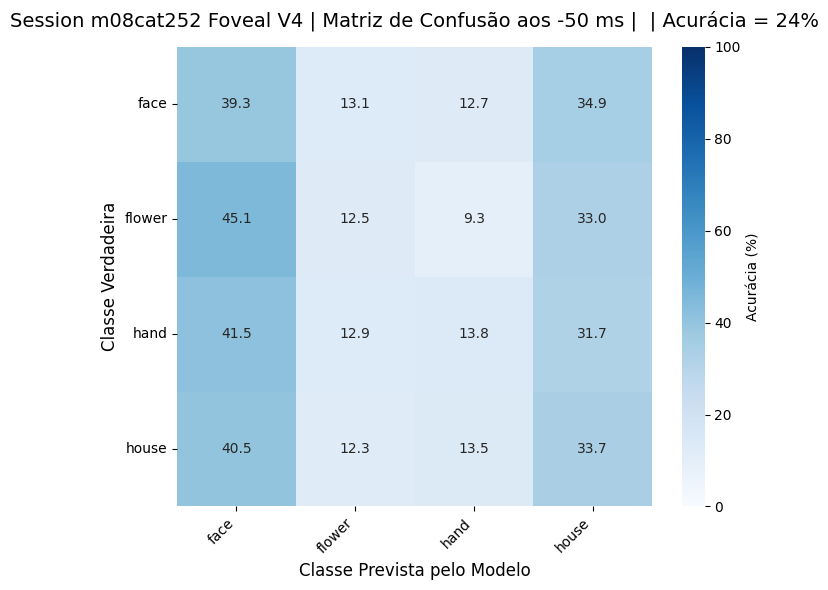

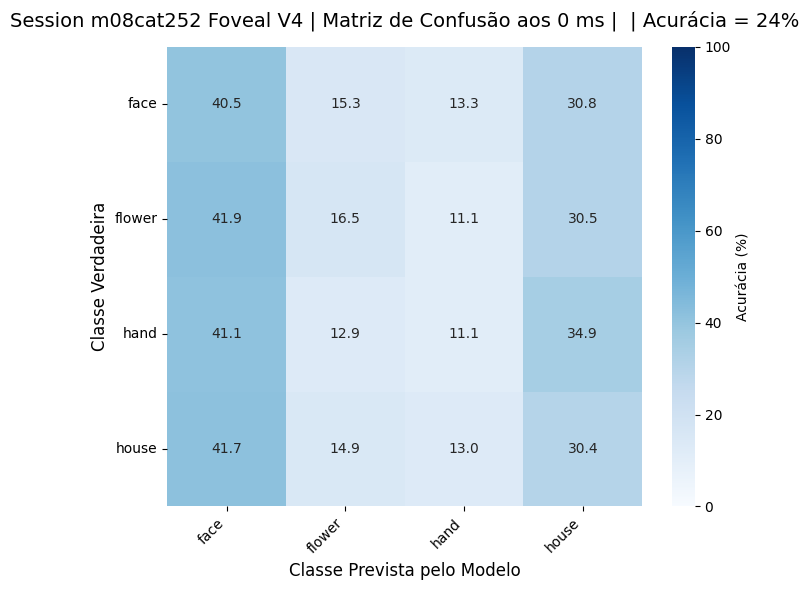

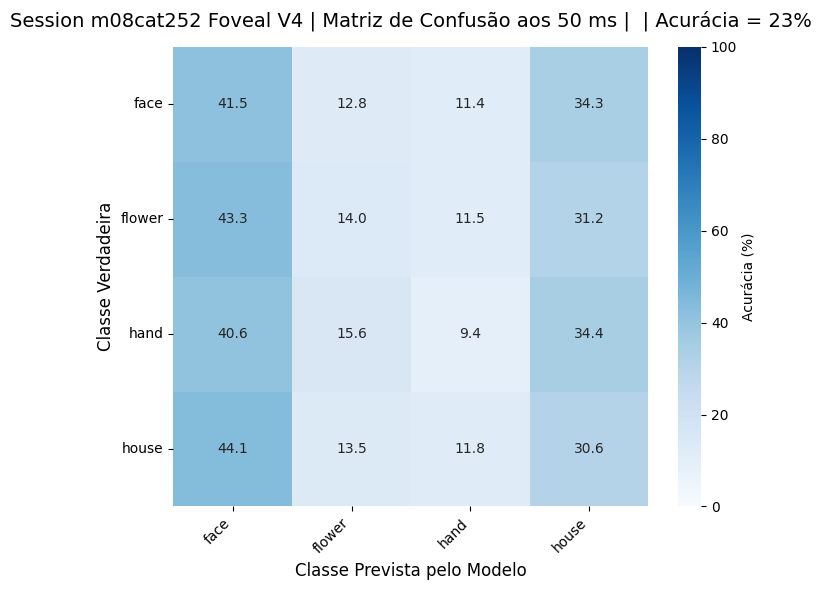

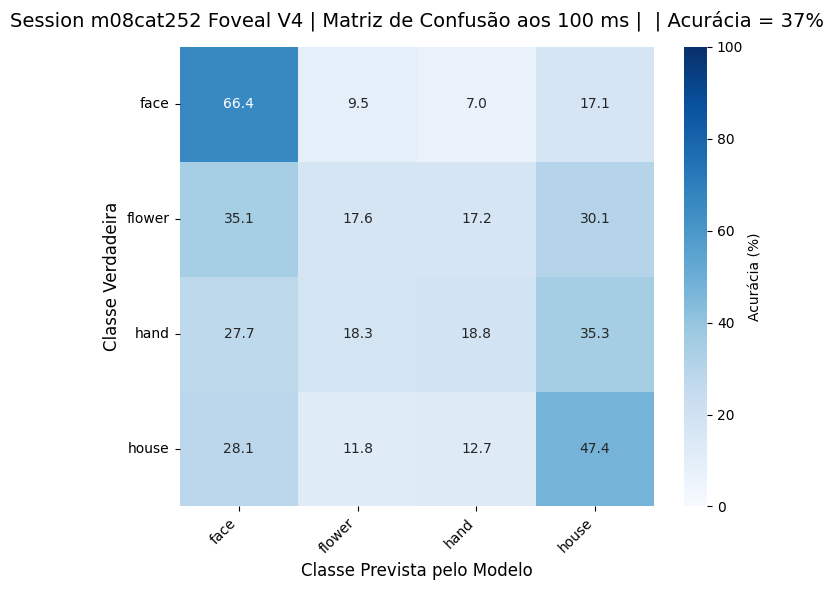

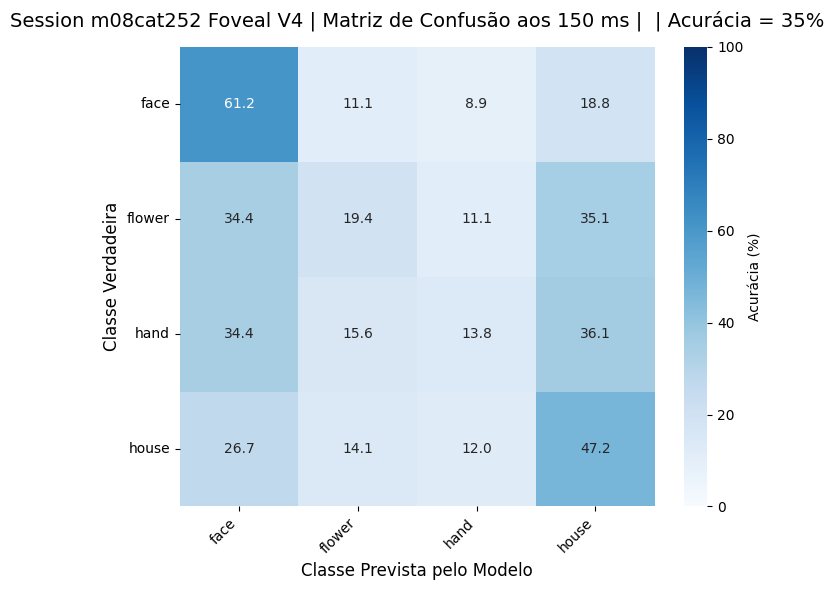

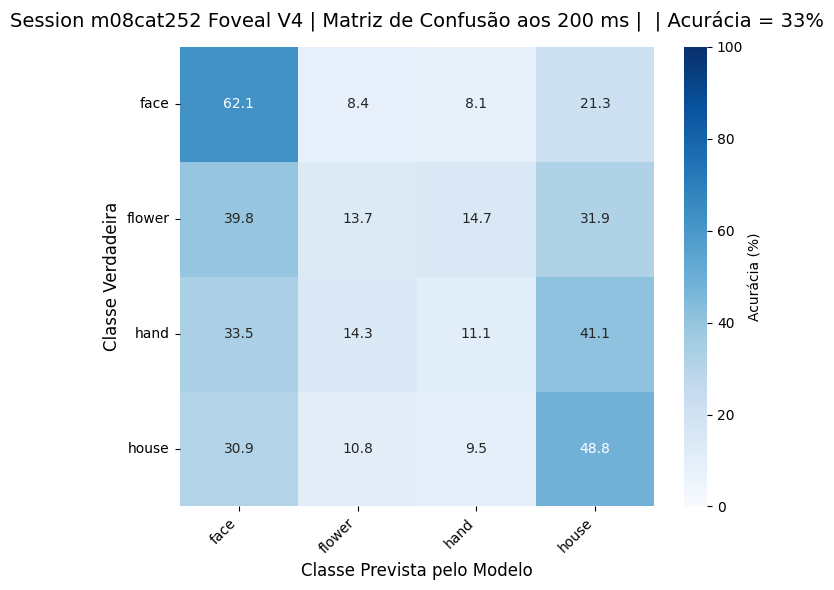

In [ ]:
plot_multiple_CM(res_category2,[-100,-50,0,50,100,150,200])

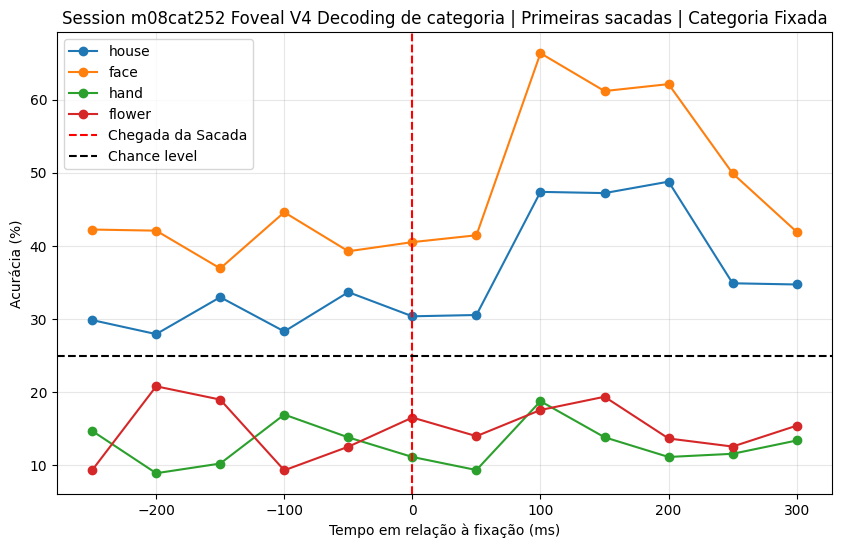

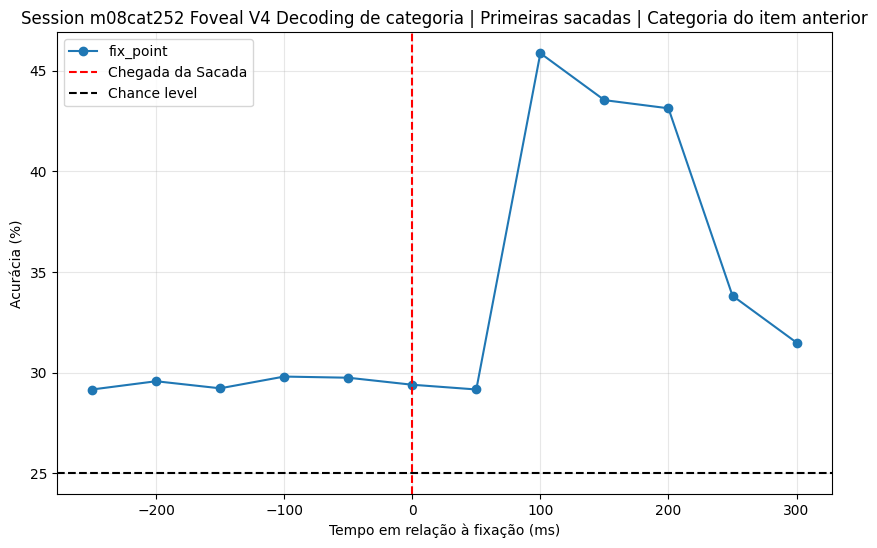

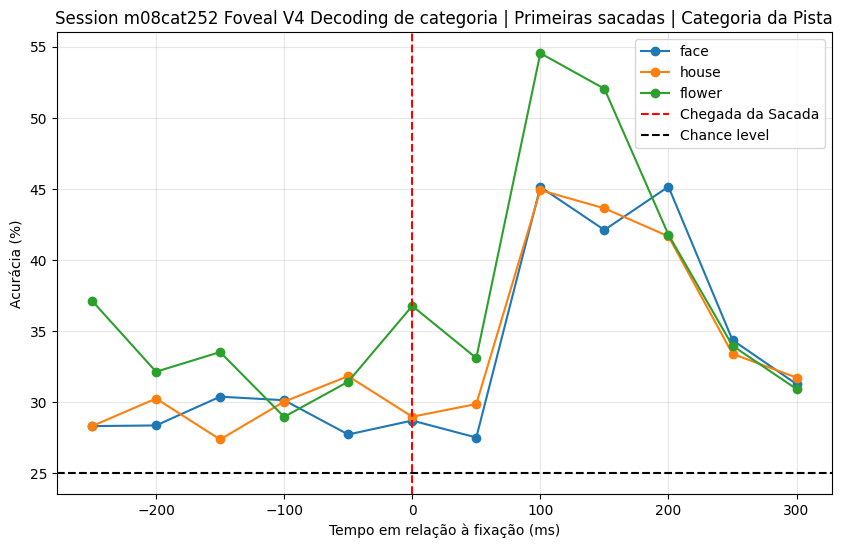

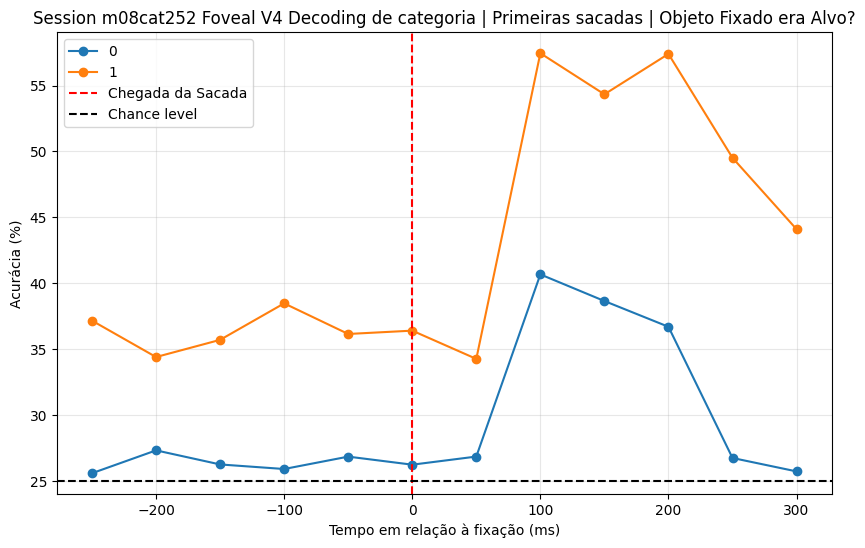

In [ ]:
txt_add_title = 'Decoding de categoria | Primeiras sacadas'

classes_plotar = ['house','face','hand','flower']
titulo_plot = 'Categoria Fixada'
plot_decoding_by_class(res_category2, 'mean_acc_cat_atual', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category2['mean_acc_cat_anterior'].keys()
titulo_plot = 'Categoria do item anterior'
plot_decoding_by_class(res_category2, 'mean_acc_cat_anterior', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category2['mean_acc_cat_cue'].keys()
titulo_plot = 'Categoria da Pista'
plot_decoding_by_class(res_category2, 'mean_acc_cat_cue', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category2['mean_acc_is_cue'].keys()
titulo_plot = 'Objeto Fixado era Alvo?'
plot_decoding_by_class(res_category2, 'mean_acc_is_cue', classes_plotar, titulo_plot, txt_add_title)


## Somente sacadas para casa ou rosto (quando estes são alvos)

In [16]:
df_trials3 = df_trials[df_trials['cue_cath'].isin(['face','house'])]
df_trials3 = df_trials3[df_trials3['sacc_img_cath'].isin(['face','house'])]
df_trials3

,neuron,prefered,brain_area,trial_num,cue_id,cue_cath,pre_sacc_time,FP_on,fix_FP,cue_on,...,sacc_num,trial+sacc,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior
1,m08cat252spk098a,face,V4,1,3004.0,face,0.136900,3.152367,4.781567,5.208733,...,1,1_1,19.0,2001.0,house,7.146267,7.149000,7.554400,8.0,flower
2,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,0,4_0,8.0,2021.0,house,14.604467,14.606267,14.748767,0.0,fix_point
3,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,1,4_1,2.0,3013.0,face,14.748767,14.750900,15.552967,8.0,house
4,m08cat252spk098a,face,V4,6,3012.0,face,0.170467,17.427567,17.604033,18.011200,...,0,6_0,19.0,3007.0,face,19.535167,19.547400,20.350700,0.0,fix_point
6,m08cat252spk098a,face,V4,8,2053.0,house,0.150233,23.919500,24.430500,24.836400,...,1,8_1,7.0,3016.0,face,26.789167,26.790900,26.917433,6.0,hand
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328872,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,3,2638_3,2.0,3017.0,face,14755.056100,14755.058000,14755.062367,1.0,face
328873,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,4,2638_4,3.0,3006.0,face,14755.062367,14755.064133,14755.070100,2.0,face
328874,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,5,2638_5,12.0,2055.0,house,14755.070100,14755.071933,14755.283267,3.0,face
328875,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,6,2638_6,3.0,3006.0,face,14755.283267,14755.285100,14755.293733,12.0,house


In [17]:
df_run_model3 = aux.get_df_run_ml(df_trials3, start_time, end_time, bin_width, step, dicio_firings)
df_run_model3

,Y_cat,Y_equality,Y_is_cue,cat_cue,cat_anterior,transition,m08cat252spk098a_Bin0,m08cat252spk098a_Bin1,m08cat252spk098a_Bin2,m08cat252spk098a_Bin3,...,m08cat252spk128z_Bin46,m08cat252spk128z_Bin47,m08cat252spk128z_Bin48,m08cat252spk128z_Bin49,m08cat252spk128z_Bin50,m08cat252spk128z_Bin51,m08cat252spk128z_Bin52,m08cat252spk128z_Bin53,m08cat252spk128z_Bin54,m08cat252spk128z_Bin55
0,house,0,0,face,flower,flower-house,40.0,40.0,40.0,20.0,...,0.0,20.0,20.0,60.0,80.0,80.0,100.0,120.0,80.0,60.0
1,house,0,0,face,fix_point,fix_point-house,40.0,20.0,0.0,20.0,...,40.0,20.0,20.0,0.0,0.0,0.0,0.0,20.0,40.0,60.0
2,face,0,1,face,house,house-face,20.0,40.0,40.0,20.0,...,80.0,60.0,60.0,40.0,40.0,20.0,20.0,20.0,0.0,20.0
3,face,0,1,face,fix_point,fix_point-face,0.0,0.0,0.0,0.0,...,80.0,80.0,60.0,40.0,80.0,80.0,60.0,40.0,60.0,20.0
4,face,0,0,house,hand,hand-face,0.0,20.0,20.0,60.0,...,40.0,20.0,40.0,20.0,20.0,40.0,40.0,20.0,20.0,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2998,face,1,0,house,face,face-face,120.0,120.0,140.0,160.0,...,20.0,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0
2999,face,1,0,house,face,face-face,100.0,140.0,160.0,140.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
3000,house,0,1,house,face,face-house,140.0,160.0,140.0,160.0,...,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3001,face,0,0,house,house,house-face,100.0,100.0,80.0,80.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
res_category3 = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model3,
    start_time=start_time,     
    decoding_type='CATEGORY',
    bin_width=bin_width,        
    step=step,             
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 56 janelas, 56 bins totais)...
Bins selecionados para Tuning: [25]
--- Processando Fold 1/5 --- 16:53:52
--- Processando Fold 2/5 --- 16:54:08
--- Processando Fold 3/5 --- 16:54:26
--- Processando Fold 4/5 --- 16:54:44
--- Processando Fold 5/5 --- 16:55:02


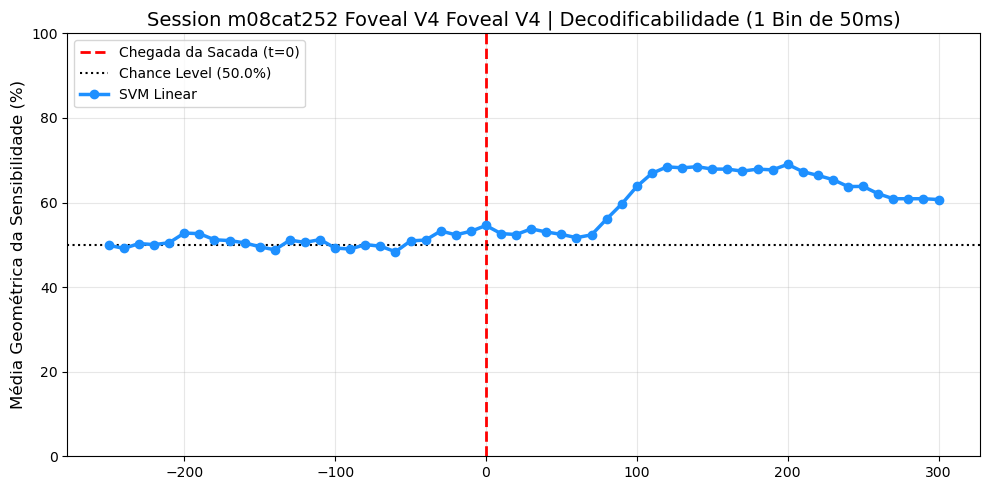

In [19]:
plot_decoding(res_category3)

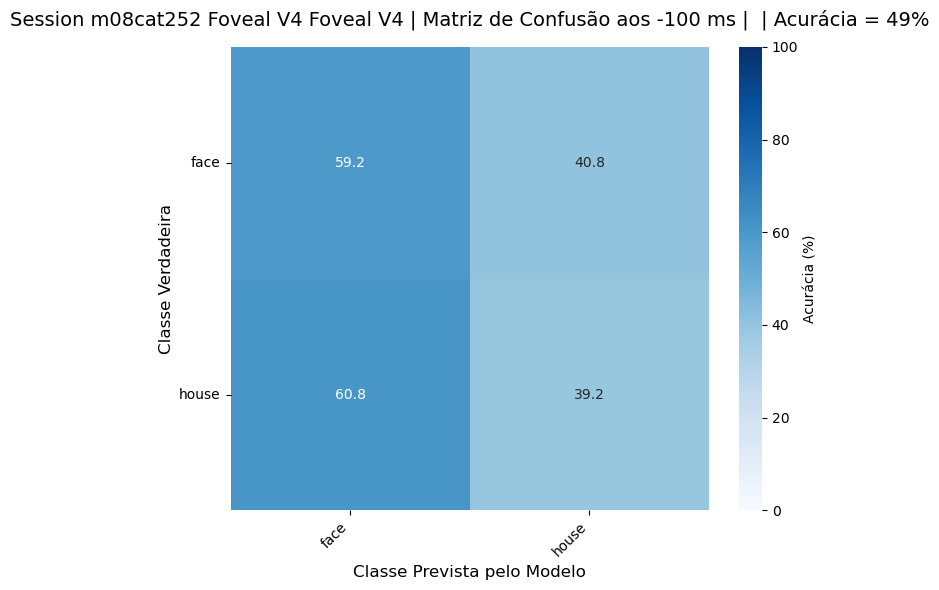

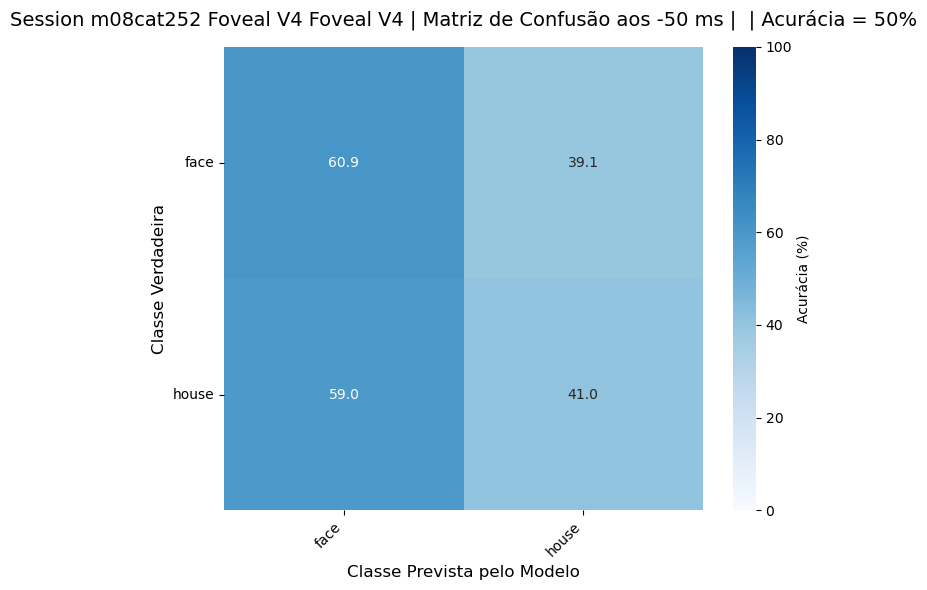

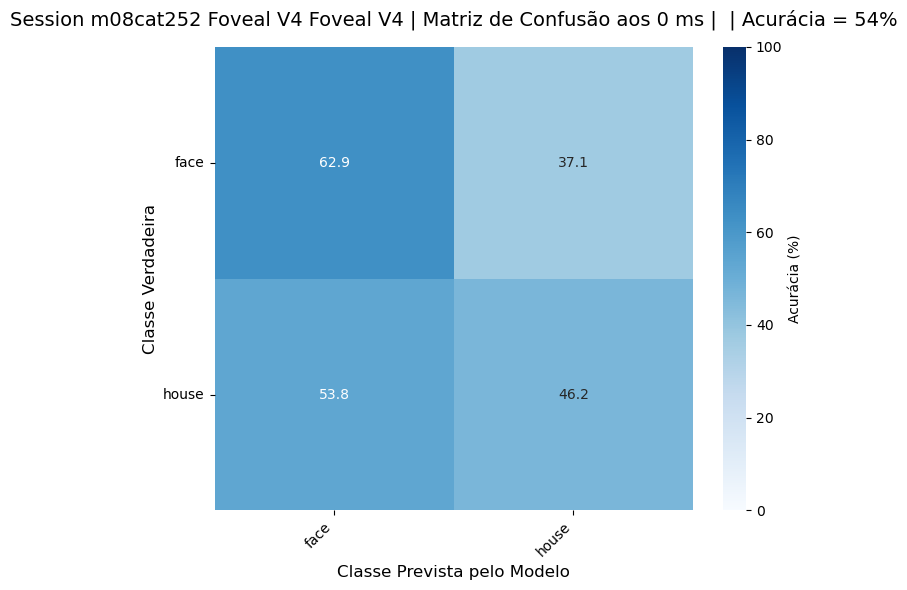

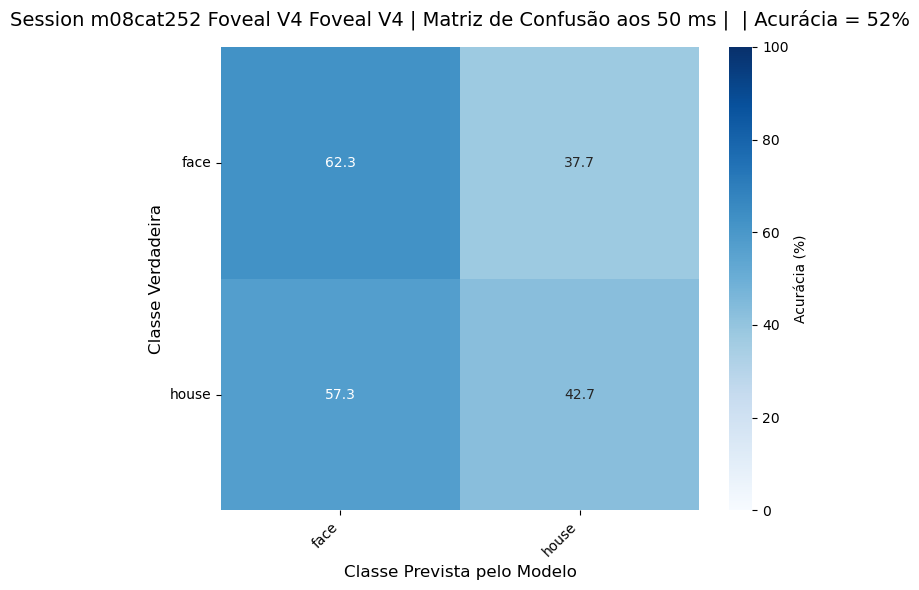

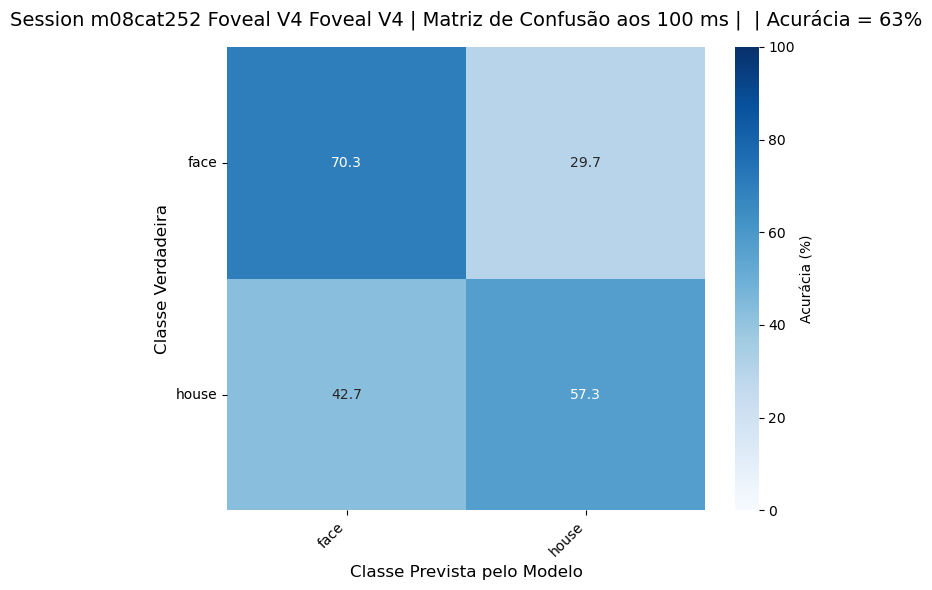

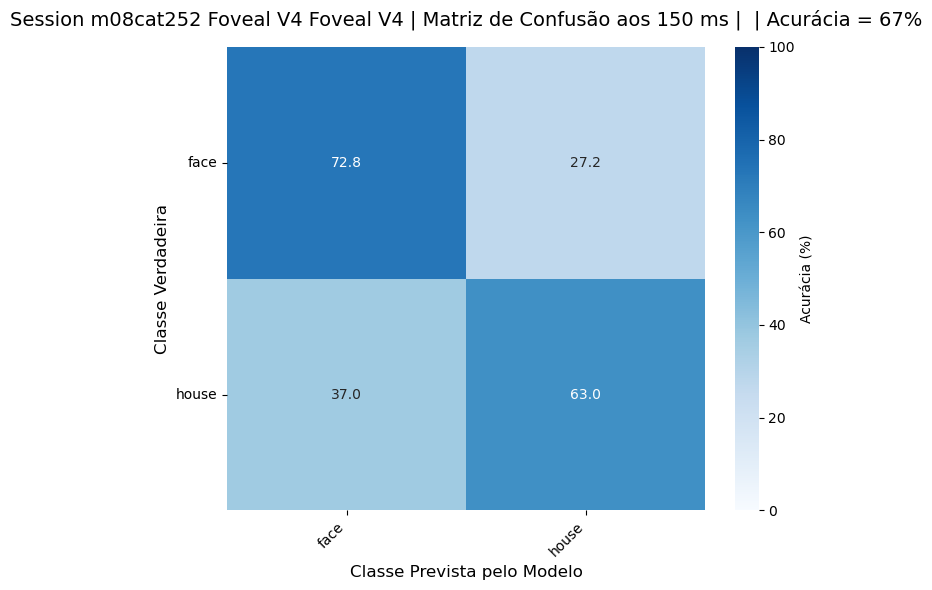

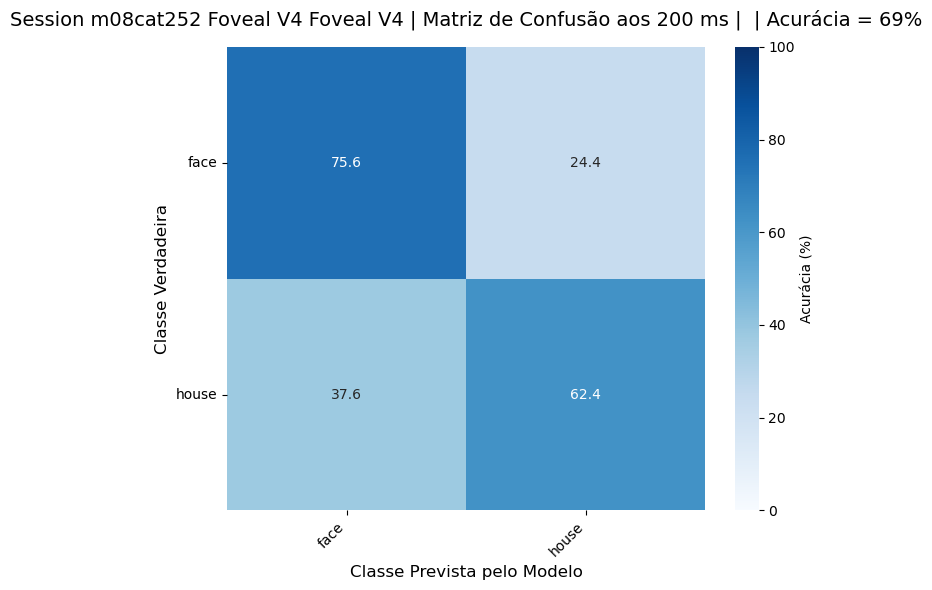

In [20]:
plot_multiple_CM(res_category3,[-100,-50,0,50,100,150,200])

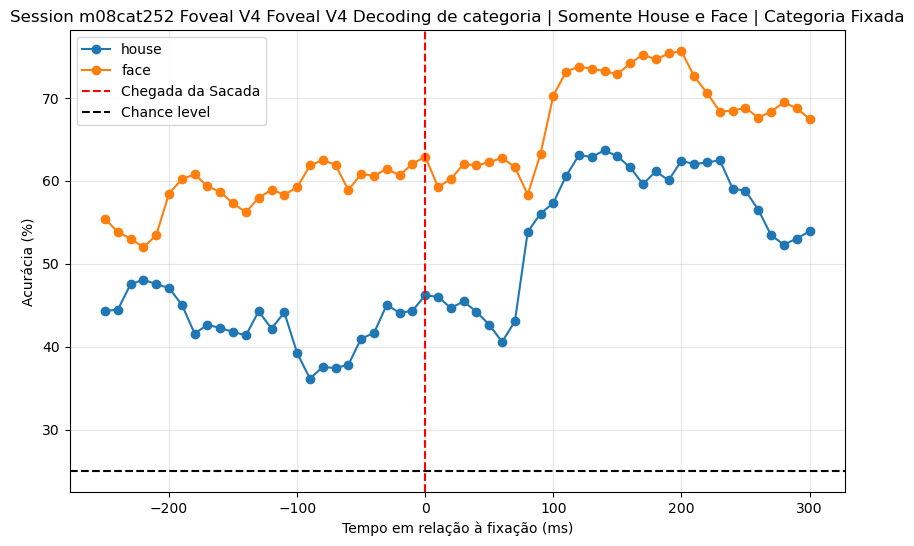

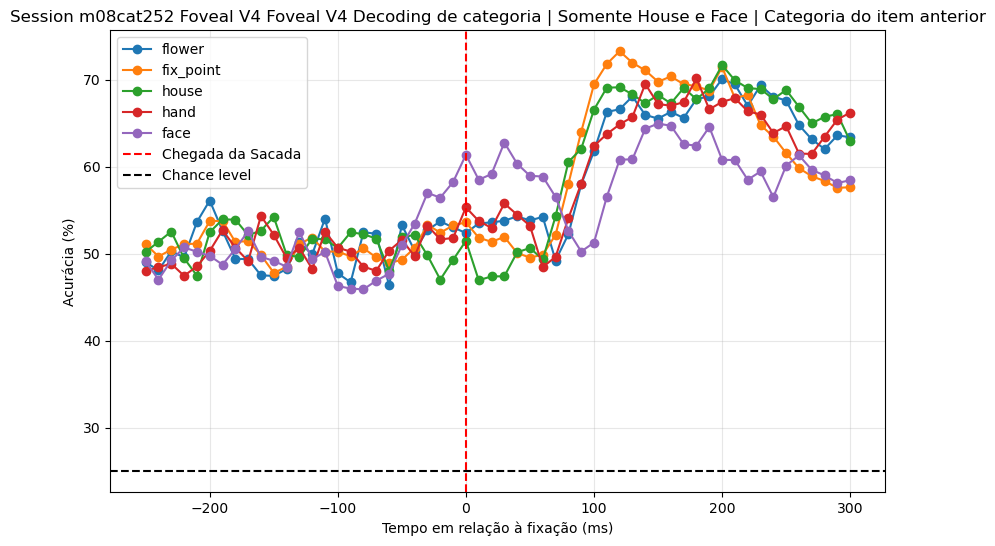

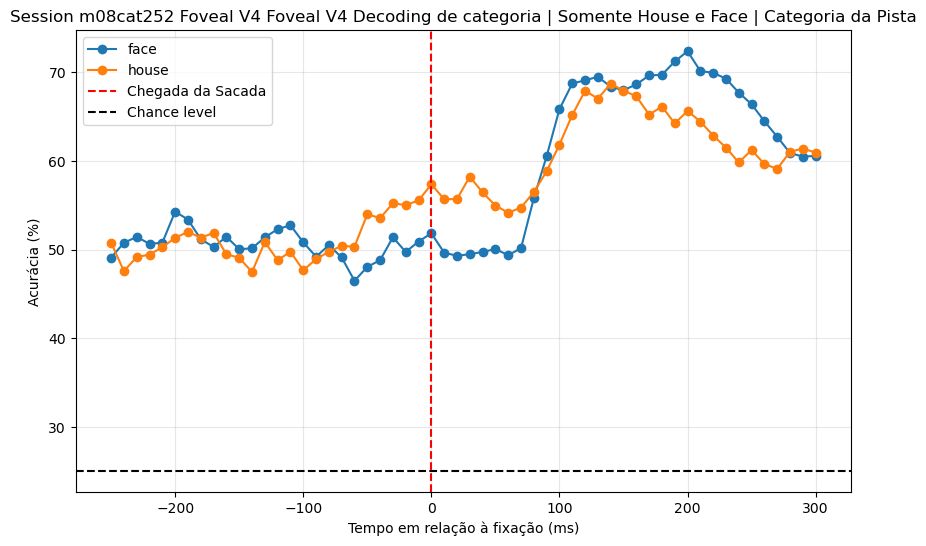

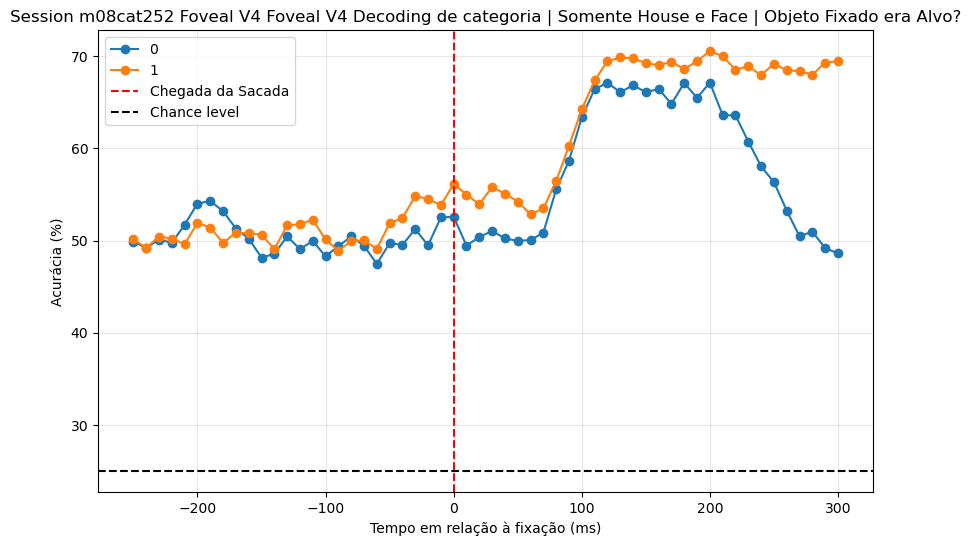

In [21]:
txt_add_title = 'Decoding de categoria | Somente House e Face'

# classes_plotar = ['house','face','hand','flower']

classes_plotar = res_category3['mean_acc_cat_atual'].keys()
titulo_plot = 'Categoria Fixada'
plot_decoding_by_class(res_category3, 'mean_acc_cat_atual', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category3['mean_acc_cat_anterior'].keys()
titulo_plot = 'Categoria do item anterior'
plot_decoding_by_class(res_category3, 'mean_acc_cat_anterior', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category3['mean_acc_cat_cue'].keys()
titulo_plot = 'Categoria da Pista'
plot_decoding_by_class(res_category3, 'mean_acc_cat_cue', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_category3['mean_acc_is_cue'].keys()
titulo_plot = 'Objeto Fixado era Alvo?'
plot_decoding_by_class(res_category3, 'mean_acc_is_cue', classes_plotar, titulo_plot, txt_add_title)

## Decoding: é a mesma categoria que estava olhando?

In [ ]:
res_change = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model,
    start_time=start_time,     
    decoding_type='CHANGE_OF_CATEGORY',
    bin_width=bin_width,        
    step=step,             
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 12 janelas, 12 bins totais)...
Bins selecionados para Tuning: [5]
--- Processando Fold 1/5 --- 18:45:00
--- Processando Fold 2/5 --- 18:45:10
--- Processando Fold 3/5 --- 18:45:16
--- Processando Fold 4/5 --- 18:45:26
--- Processando Fold 5/5 --- 18:45:32


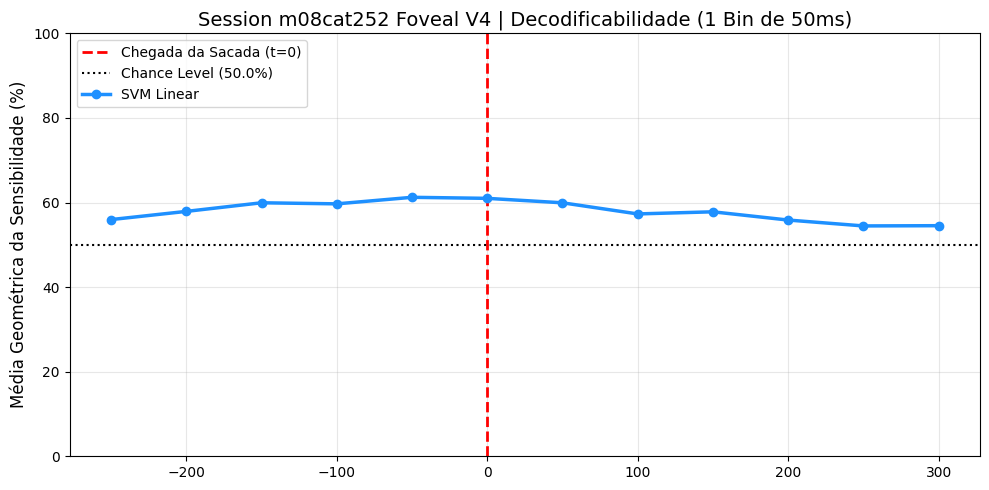

In [ ]:
plot_decoding(res_change)

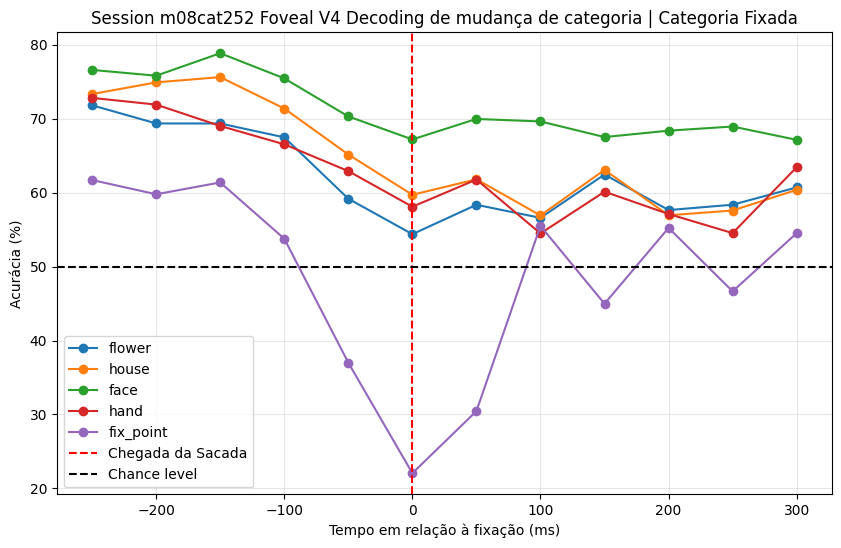

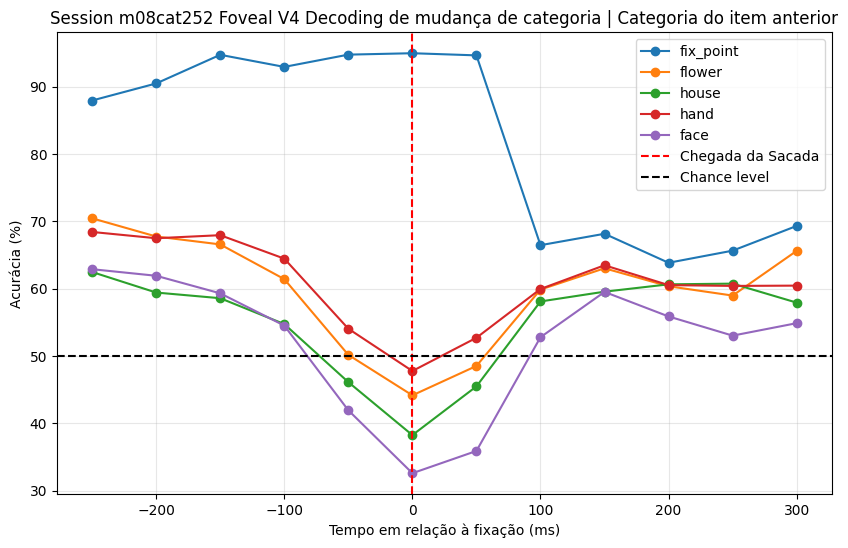

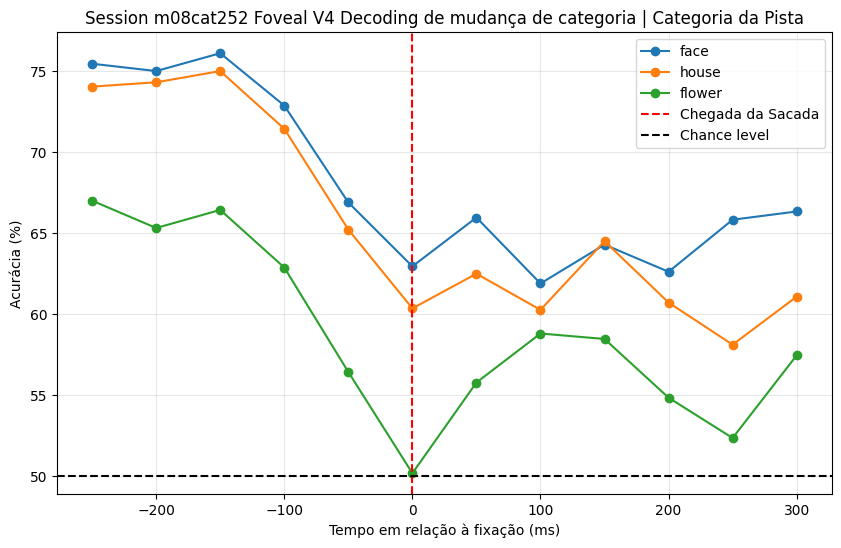

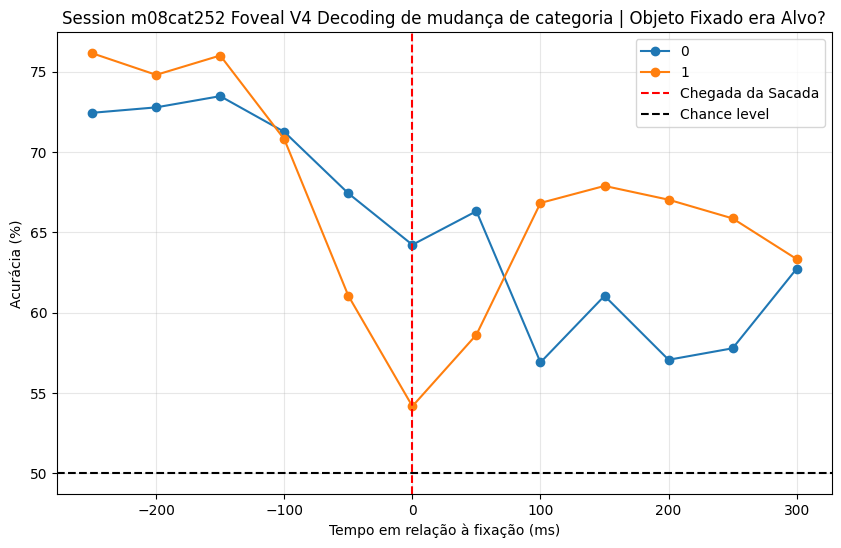

In [ ]:
txt_add_title = 'Decoding de mudança de categoria'

# classes_plotar = ['house','face','hand','flower']
classes_plotar = res_change['mean_acc_cat_atual'].keys()
titulo_plot = 'Categoria Fixada'
plot_decoding_by_class(res_change, 'mean_acc_cat_atual', classes_plotar, titulo_plot, txt_add_title, 50)

classes_plotar = res_change['mean_acc_cat_anterior'].keys()
titulo_plot = 'Categoria do item anterior'
plot_decoding_by_class(res_change, 'mean_acc_cat_anterior', classes_plotar, titulo_plot, txt_add_title, 50)

classes_plotar = res_change['mean_acc_cat_cue'].keys()
titulo_plot = 'Categoria da Pista'
plot_decoding_by_class(res_change, 'mean_acc_cat_cue', classes_plotar, titulo_plot, txt_add_title, 50)

classes_plotar = res_change['mean_acc_is_cue'].keys()
titulo_plot = 'Objeto Fixado era Alvo?'
plot_decoding_by_class(res_change, 'mean_acc_is_cue', classes_plotar, titulo_plot, txt_add_title, 50)


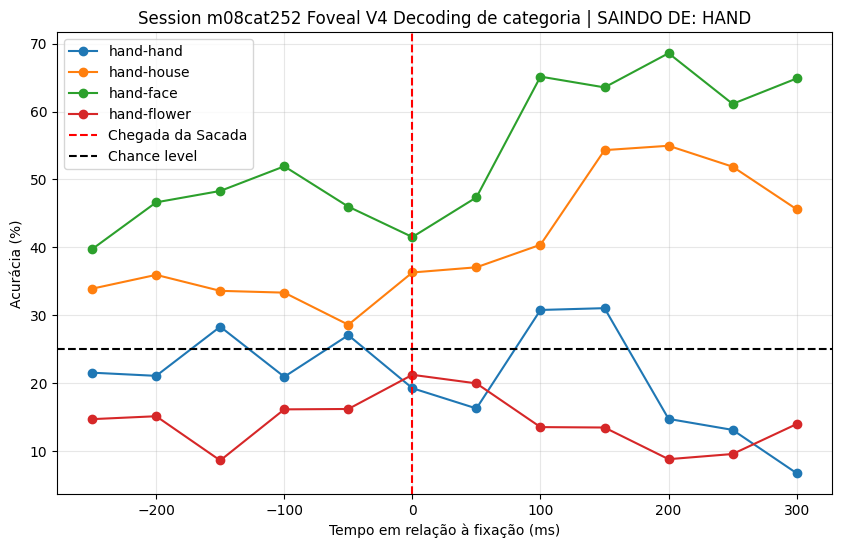

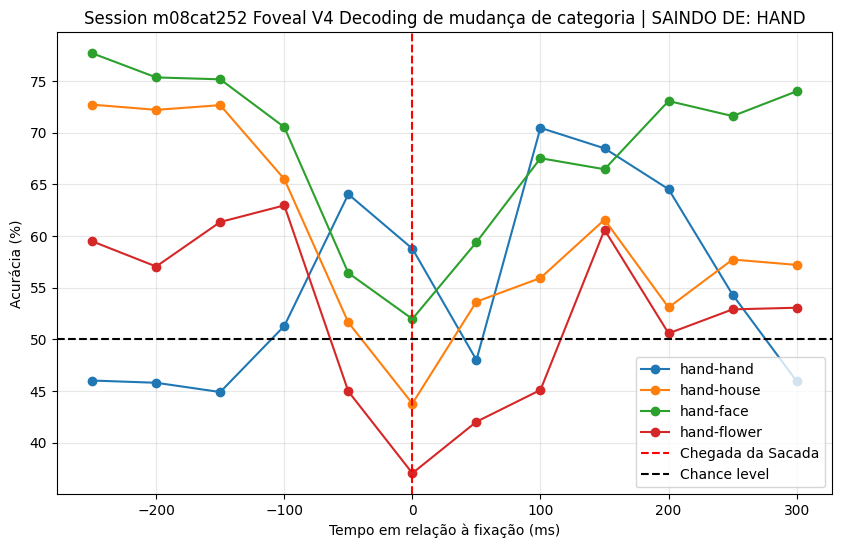

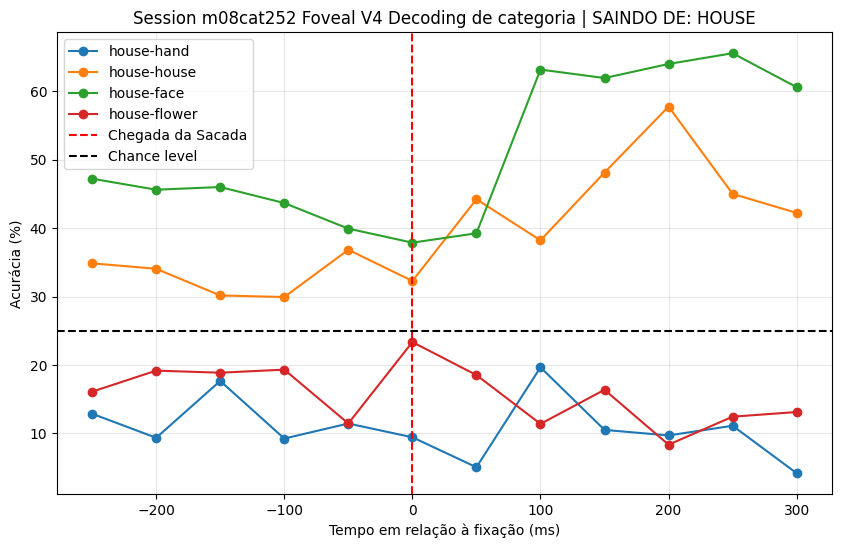

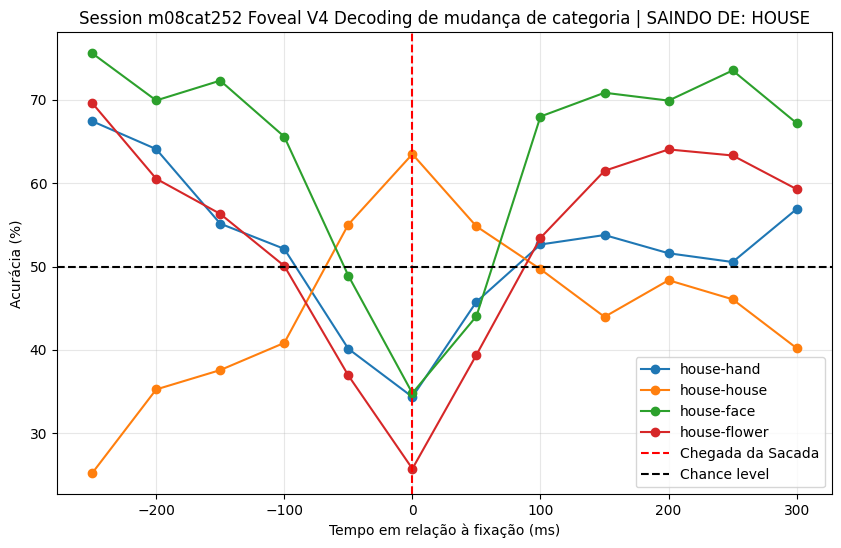

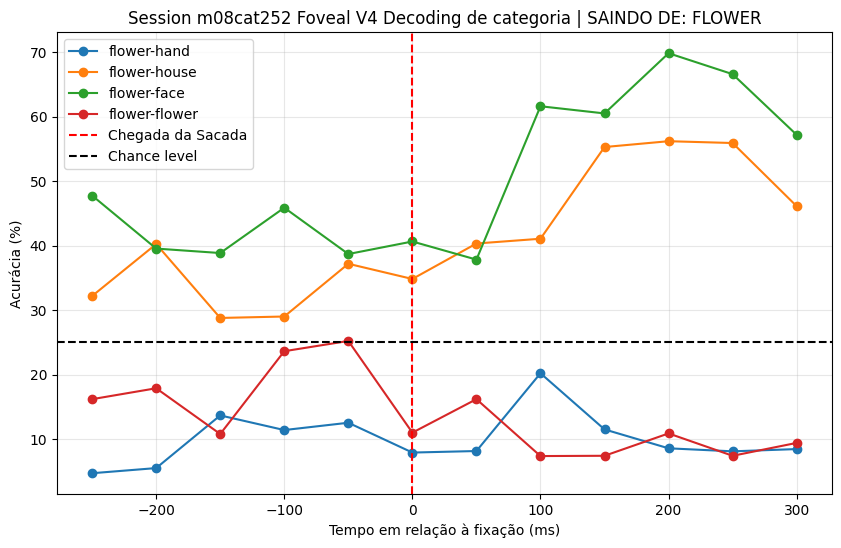

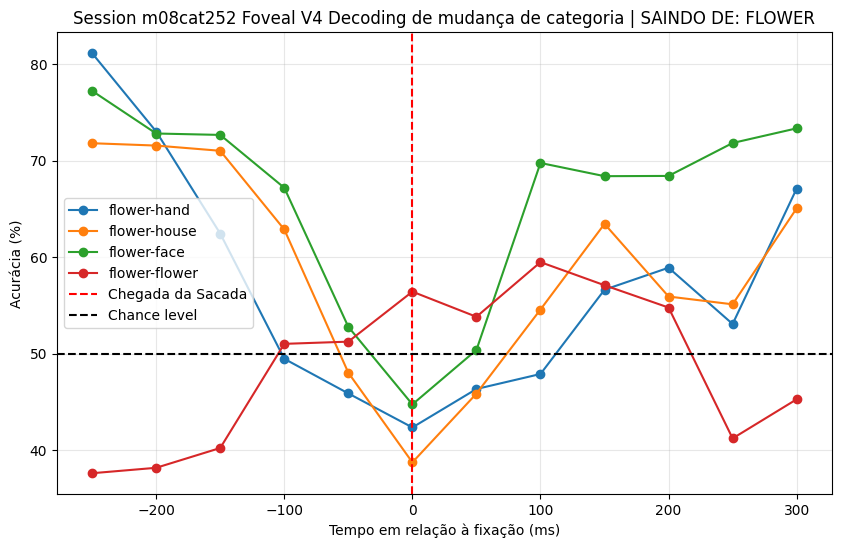

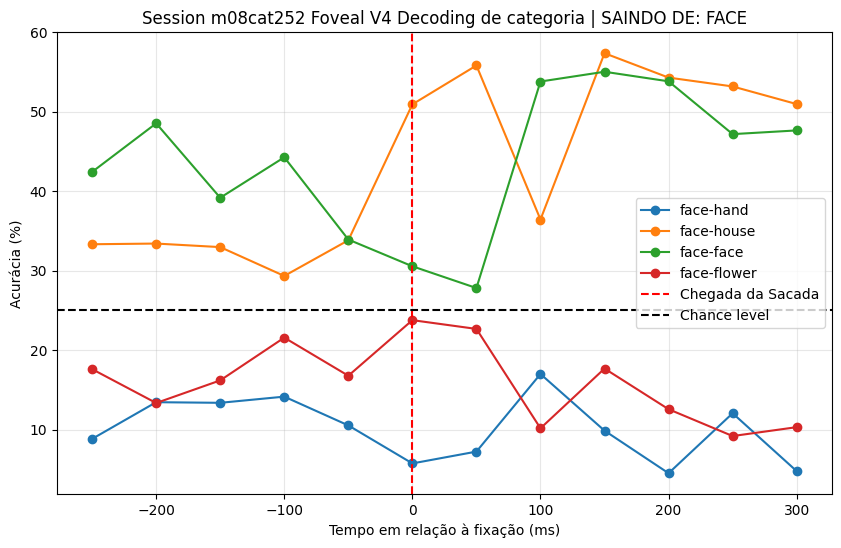

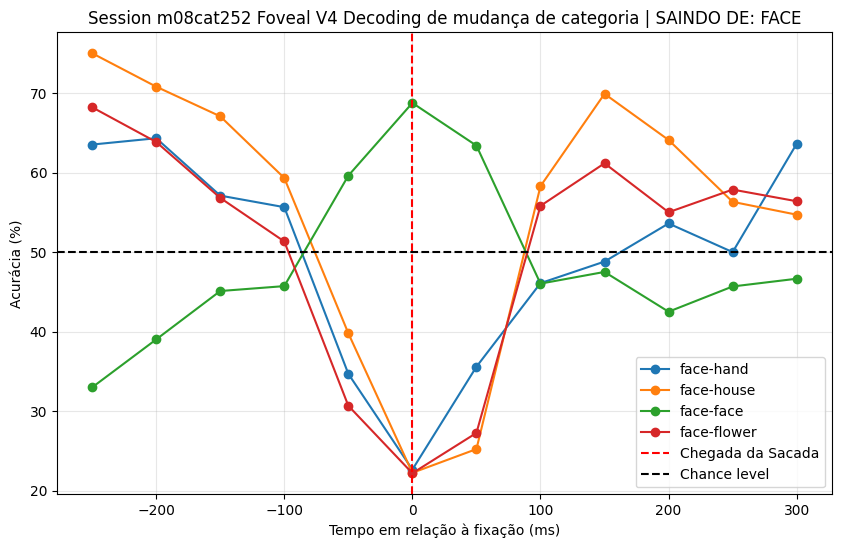

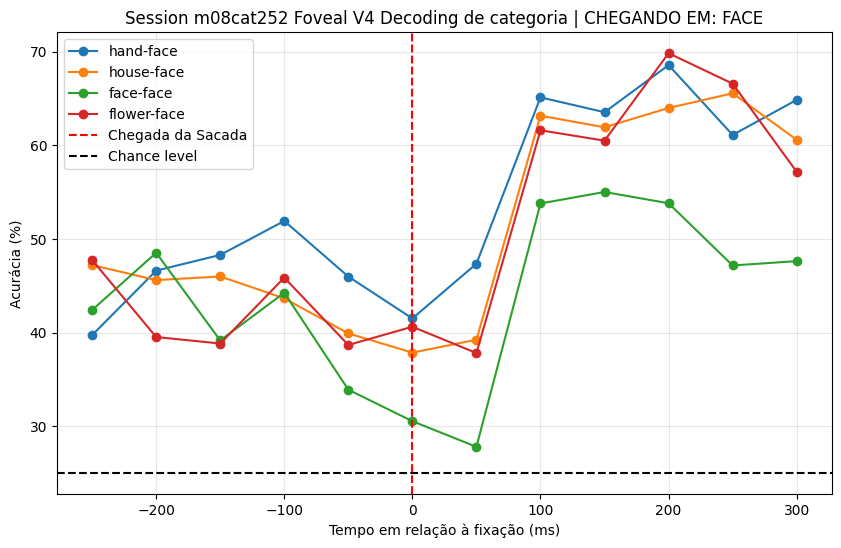

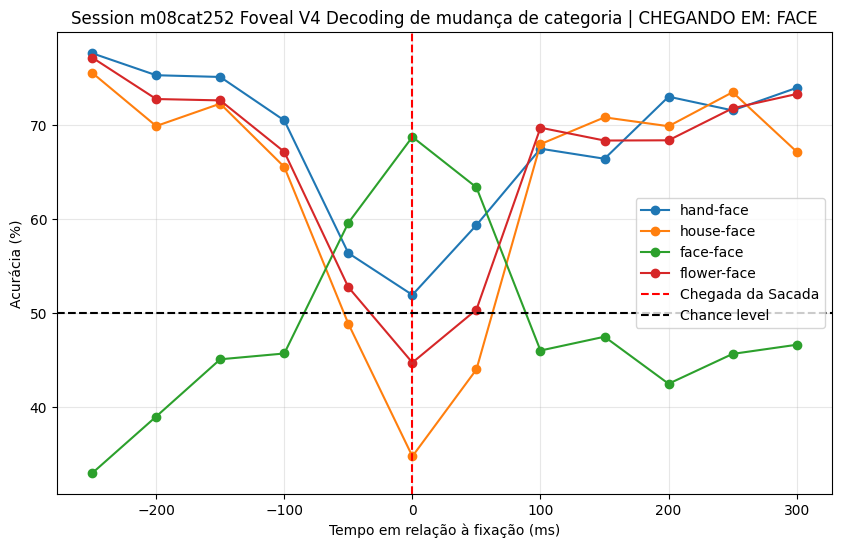

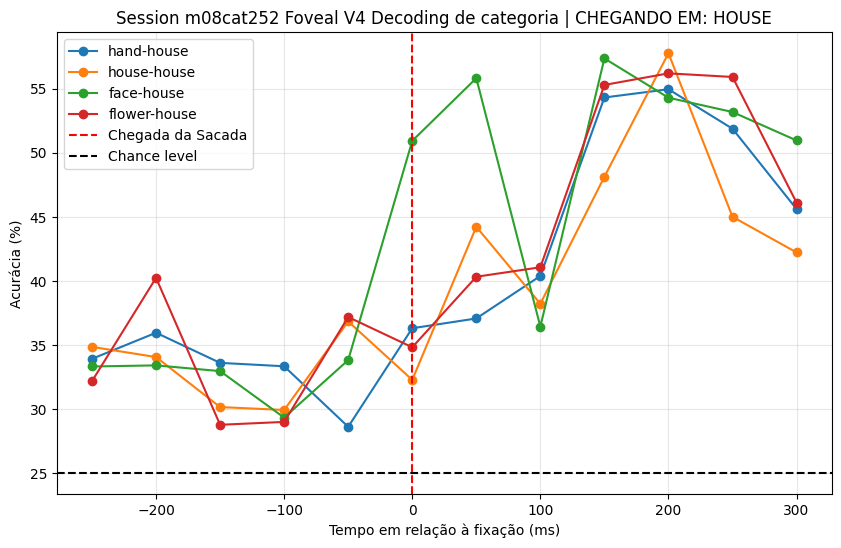

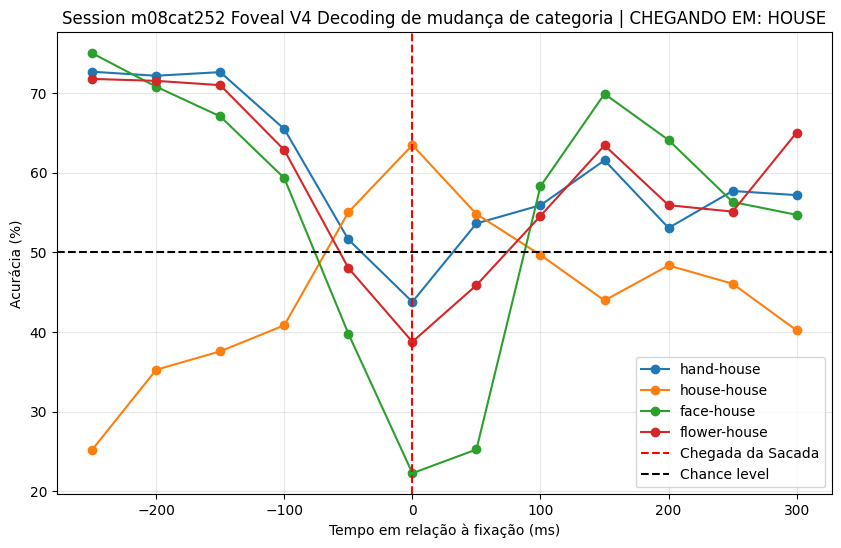

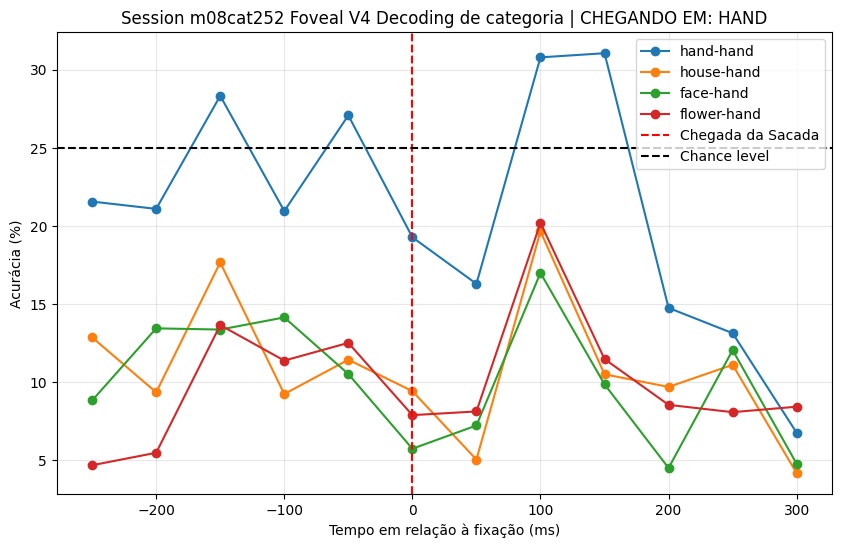

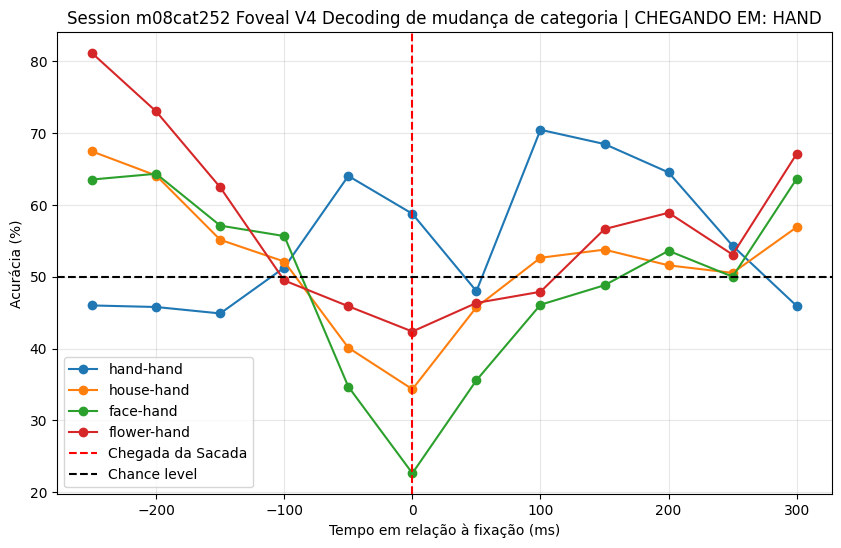

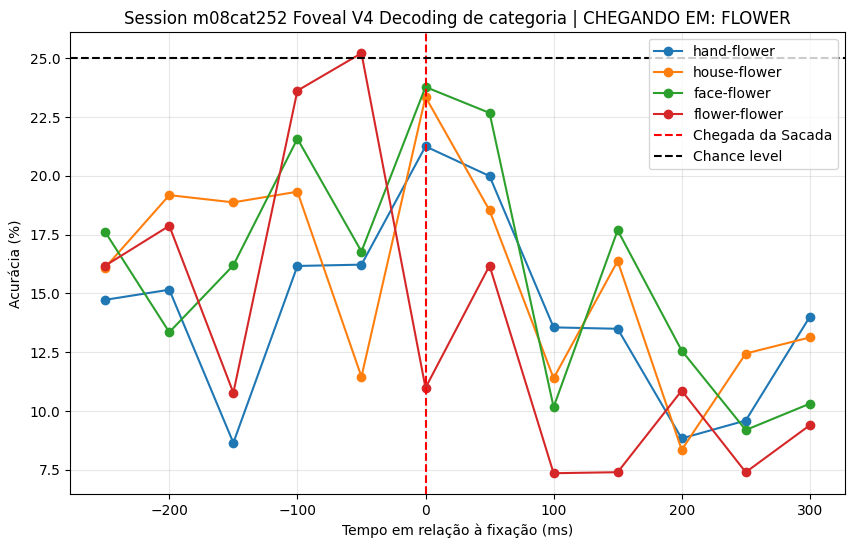

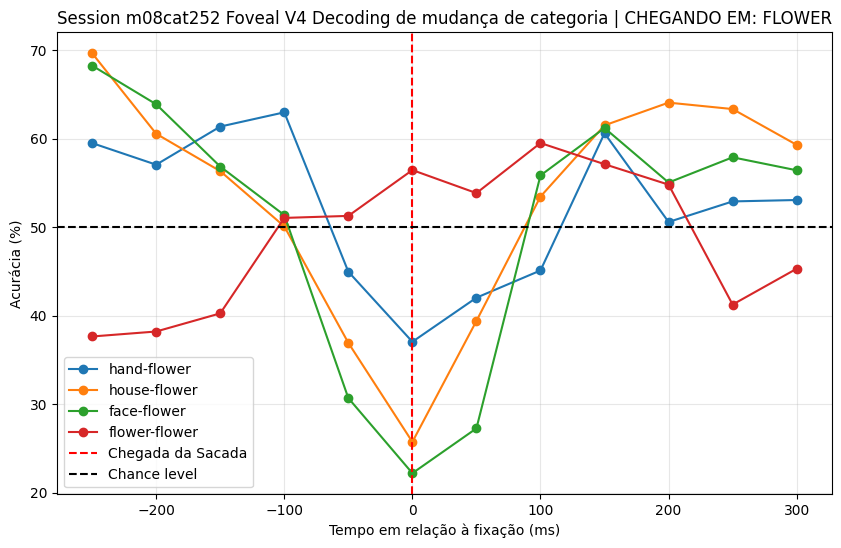

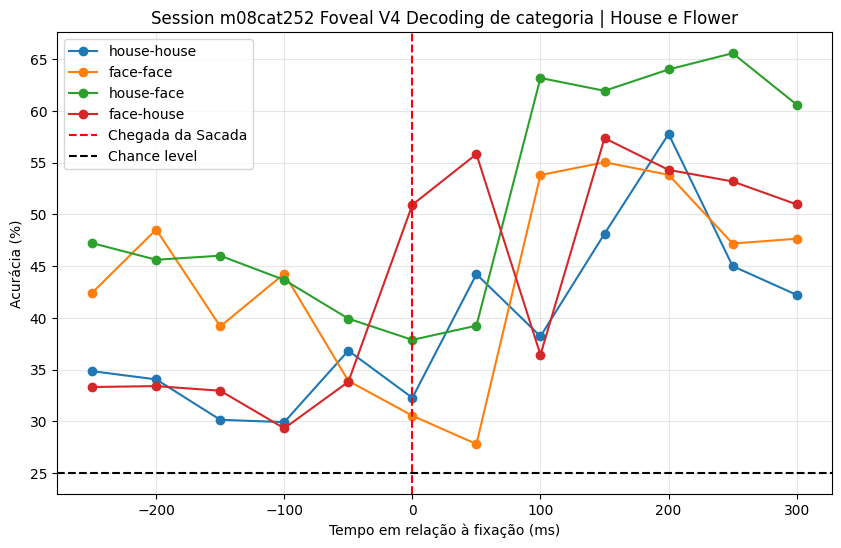

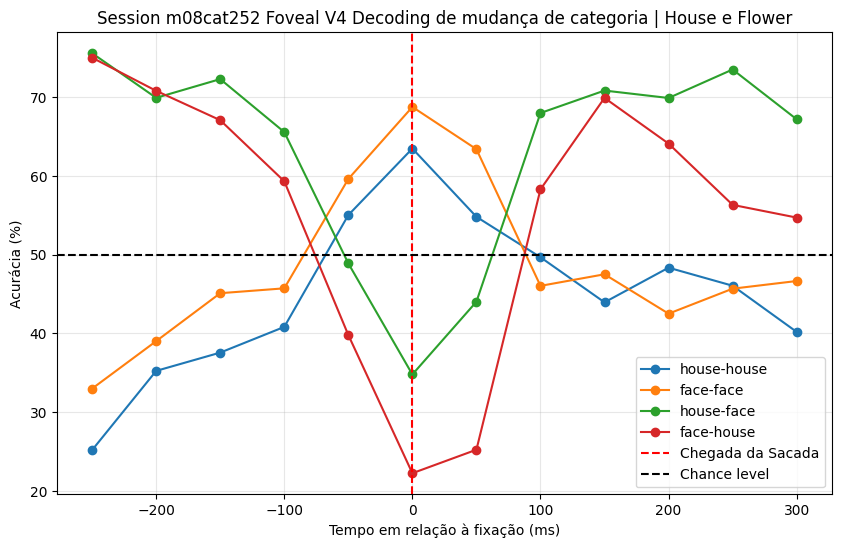

In [ ]:
txt_add_title1 = 'Decoding de categoria'
txt_add_title2 = 'Decoding de mudança de categoria'

classes_plotar = ['hand-hand','hand-house','hand-face','hand-flower']
titulo_plot = 'SAINDO DE: HAND'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['house-hand','house-house','house-face','house-flower']
titulo_plot = 'SAINDO DE: HOUSE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['flower-hand','flower-house','flower-face','flower-flower']
titulo_plot = 'SAINDO DE: FLOWER'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['face-hand','face-house','face-face','face-flower']
titulo_plot = 'SAINDO DE: FACE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['hand-face','house-face','face-face','flower-face']
titulo_plot = 'CHEGANDO EM: FACE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['hand-house','house-house','face-house','flower-house']
titulo_plot = 'CHEGANDO EM: HOUSE'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['hand-hand','house-hand','face-hand','flower-hand']
titulo_plot = 'CHEGANDO EM: HAND'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['hand-flower','house-flower','face-flower','flower-flower']
titulo_plot = 'CHEGANDO EM: FLOWER'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)

classes_plotar = ['house-house','face-face', 'house-face','face-house']
titulo_plot = 'House e Flower'
plot_decoding_by_class(res_category, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title1)
plot_decoding_by_class(res_change, 'mean_acc_transition', classes_plotar, titulo_plot, txt_add_title2,50)



## Decoding categoria anterior

In [25]:
df_trials4 = df_trials[df_trials['img_cath_anterior'].isin(['face','house','flower','hand'])]
df_trials4

,neuron,prefered,brain_area,trial_num,cue_id,cue_cath,pre_sacc_time,FP_on,fix_FP,cue_on,...,sacc_num,trial+sacc,sacc_stim_loc,sacc_img_id,sacc_img_cath,sacc_start_time,fix_time,fix_end_time,stim_loc_anterior,img_cath_anterior
1,m08cat252spk098a,face,V4,1,3004.0,face,0.136900,3.152367,4.781567,5.208733,...,1,1_1,19.0,2001.0,house,7.146267,7.149000,7.554400,8.0,flower
3,m08cat252spk098a,face,V4,4,3033.0,face,0.127767,12.852000,13.009967,13.414833,...,1,4_1,2.0,3013.0,face,14.748767,14.750900,15.552967,8.0,house
6,m08cat252spk098a,face,V4,8,2053.0,house,0.150233,23.919500,24.430500,24.836400,...,1,8_1,7.0,3016.0,face,26.789167,26.790900,26.917433,6.0,hand
7,m08cat252spk098a,face,V4,8,2053.0,house,0.150233,23.919500,24.430500,24.836400,...,2,8_2,17.0,3006.0,face,26.917433,26.919467,27.030033,7.0,face
8,m08cat252spk098a,face,V4,8,2053.0,house,0.150233,23.919500,24.430500,24.836400,...,3,8_3,19.0,2026.0,house,27.030033,27.037967,27.842400,17.0,face
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
328873,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,4,2638_4,3.0,3006.0,face,14755.062367,14755.064133,14755.070100,2.0,face
328874,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,5,2638_5,12.0,2055.0,house,14755.070100,14755.071933,14755.283267,3.0,face
328875,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,6,2638_6,3.0,3006.0,face,14755.283267,14755.285100,14755.293733,12.0,house
328876,m08cat252spk128z,NaN,V4,2638,2055.0,house,0.079167,14750.141967,14750.349567,14750.753233,...,7,2638_7,4.0,1012.0,flower,14755.293733,14755.296600,14755.447033,3.0,face


In [26]:
df_run_model4 = aux.get_df_run_ml(df_trials4, start_time, end_time, bin_width, step, dicio_firings)
df_run_model4

,Y_cat,Y_equality,Y_is_cue,cat_cue,cat_anterior,transition,m08cat252spk098a_Bin0,m08cat252spk098a_Bin1,m08cat252spk098a_Bin2,m08cat252spk098a_Bin3,...,m08cat252spk128z_Bin46,m08cat252spk128z_Bin47,m08cat252spk128z_Bin48,m08cat252spk128z_Bin49,m08cat252spk128z_Bin50,m08cat252spk128z_Bin51,m08cat252spk128z_Bin52,m08cat252spk128z_Bin53,m08cat252spk128z_Bin54,m08cat252spk128z_Bin55
0,house,0,0,face,flower,flower-house,40.0,40.0,40.0,20.0,...,0.0,20.0,20.0,60.0,80.0,80.0,100.0,120.0,80.0,60.0
1,face,0,1,face,house,house-face,20.0,40.0,40.0,20.0,...,80.0,60.0,60.0,40.0,40.0,20.0,20.0,20.0,0.0,20.0
2,face,0,0,house,hand,hand-face,0.0,20.0,20.0,60.0,...,40.0,20.0,40.0,20.0,20.0,40.0,40.0,20.0,20.0,20.0
3,face,1,0,house,face,face-face,60.0,60.0,20.0,20.0,...,20.0,40.0,60.0,120.0,100.0,100.0,120.0,120.0,80.0,100.0
4,house,0,1,house,face,face-house,40.0,40.0,40.0,20.0,...,60.0,40.0,40.0,60.0,40.0,60.0,60.0,40.0,40.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3139,face,1,0,house,face,face-face,100.0,140.0,160.0,140.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
3140,house,0,1,house,face,face-house,140.0,160.0,140.0,160.0,...,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3141,face,0,0,house,house,house-face,100.0,100.0,80.0,80.0,...,20.0,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
3142,flower,0,0,house,face,face-flower,80.0,80.0,80.0,80.0,...,20.0,20.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0


In [27]:
importlib.reload(aux)

<module 'aux_functions' from '/media/kaori/PortableSSD/vispred/aux_functions.py'>

In [28]:
res_prevcat = aux.run_temporal_decoding_generic(
    df_run_model=df_run_model4,
    start_time=start_time,     
    decoding_type='PREV_CATEGORY',
    bin_width=bin_width,        
    step=step,             
    # window_size_bins=4   
    window_size_bins=1   
)

Iniciando Decoding (5 folds, 56 janelas, 56 bins totais)...
Bins selecionados para Tuning: [25]
--- Processando Fold 1/5 --- 17:07:43
--- Processando Fold 2/5 --- 17:08:08
--- Processando Fold 3/5 --- 17:08:28
--- Processando Fold 4/5 --- 17:08:52
--- Processando Fold 5/5 --- 17:09:16


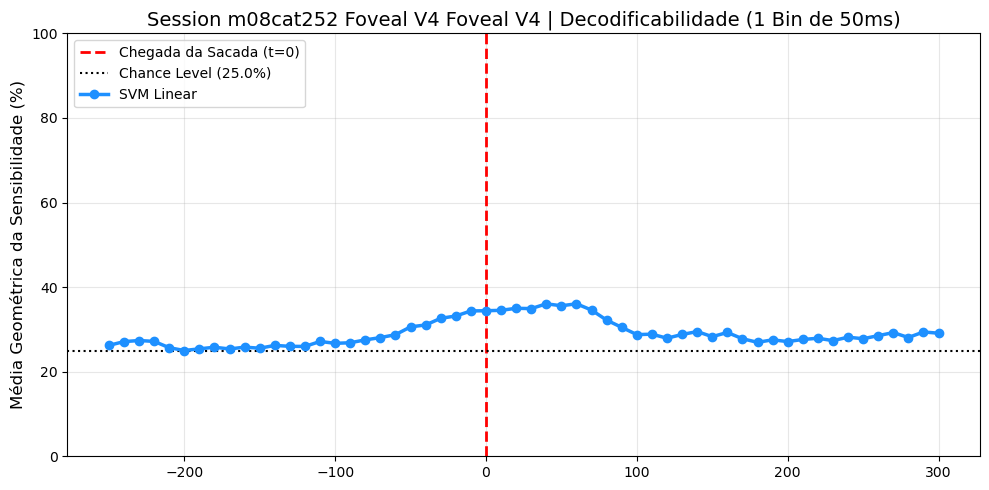

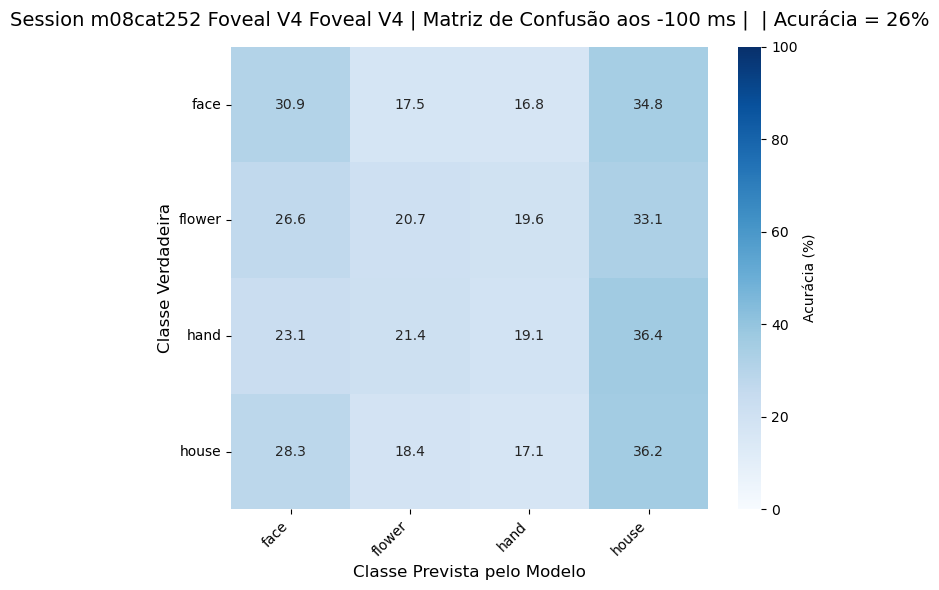

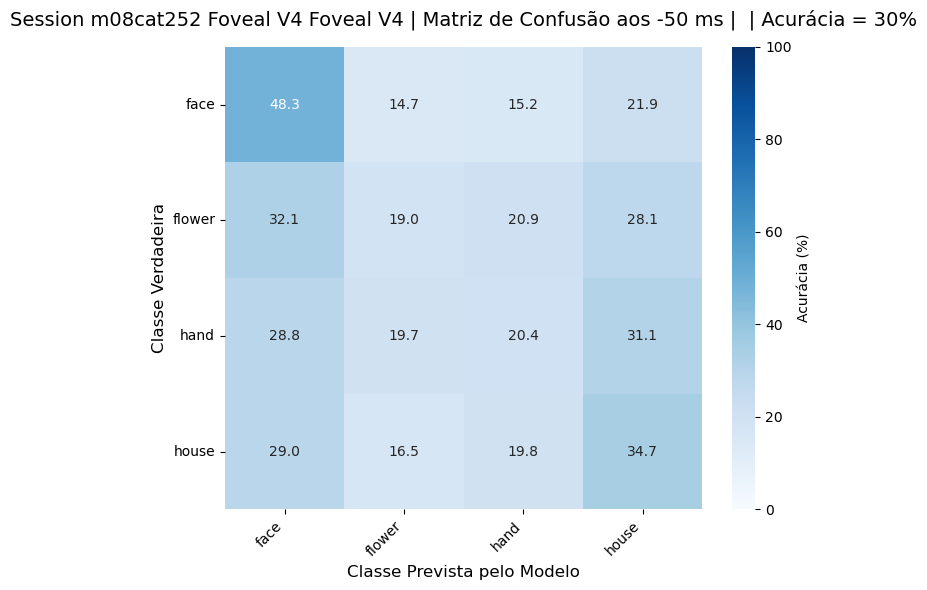

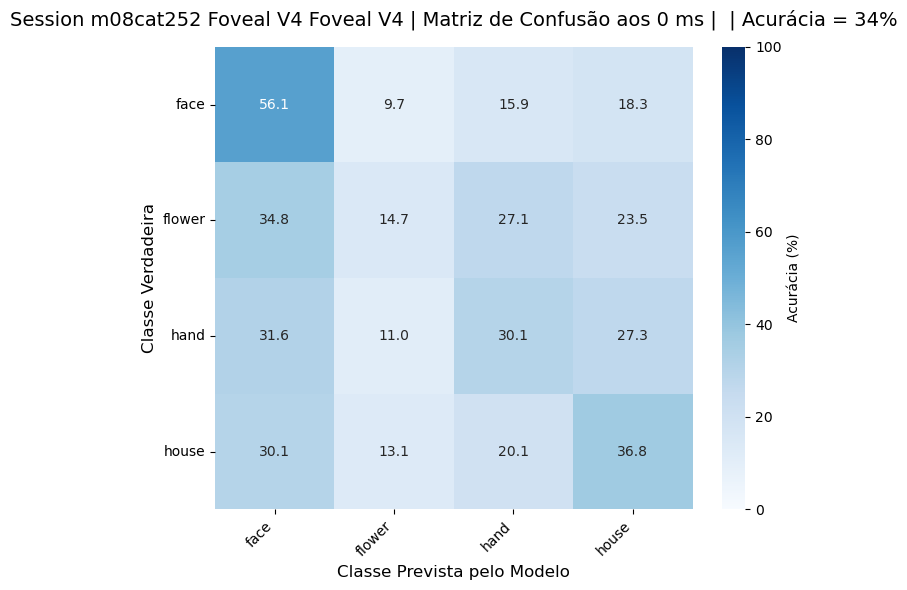

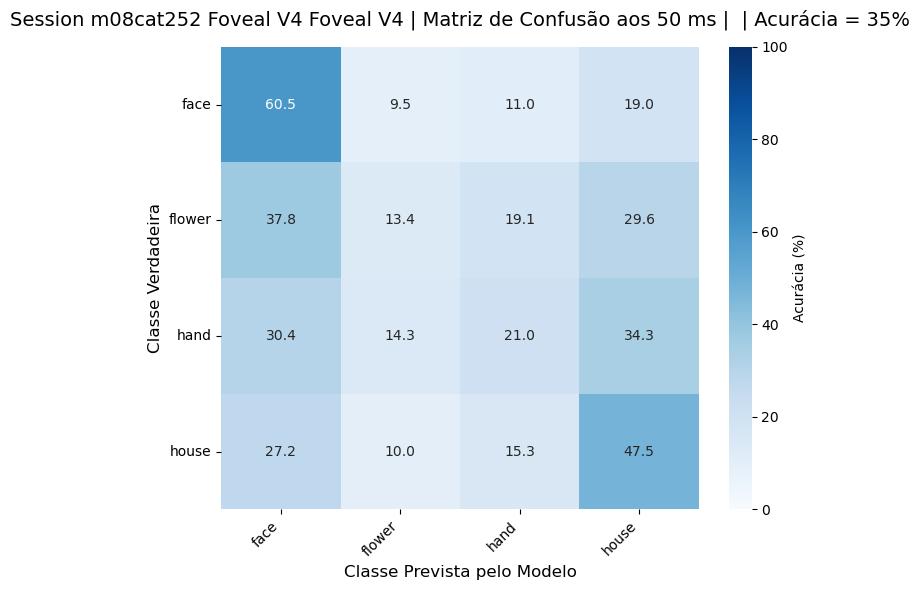

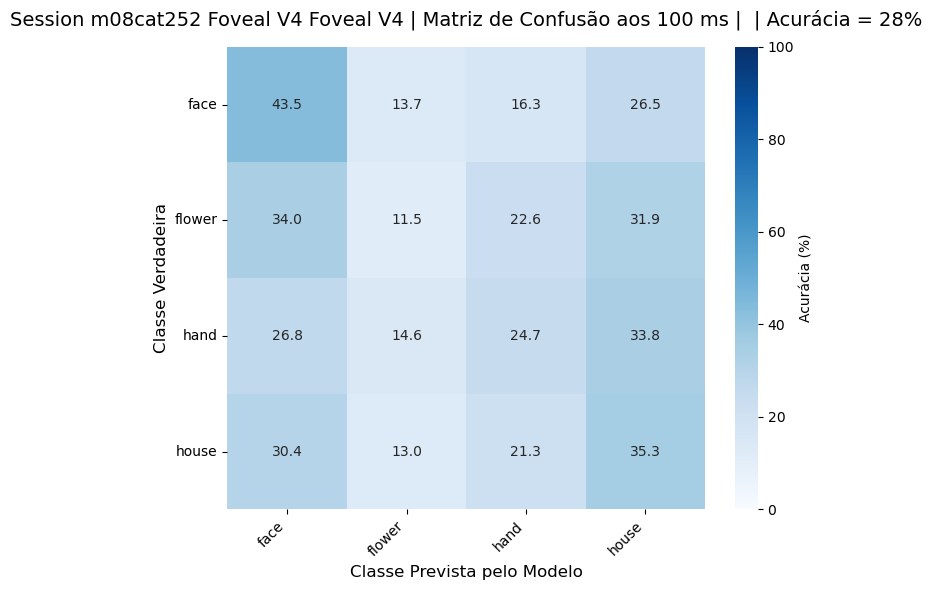

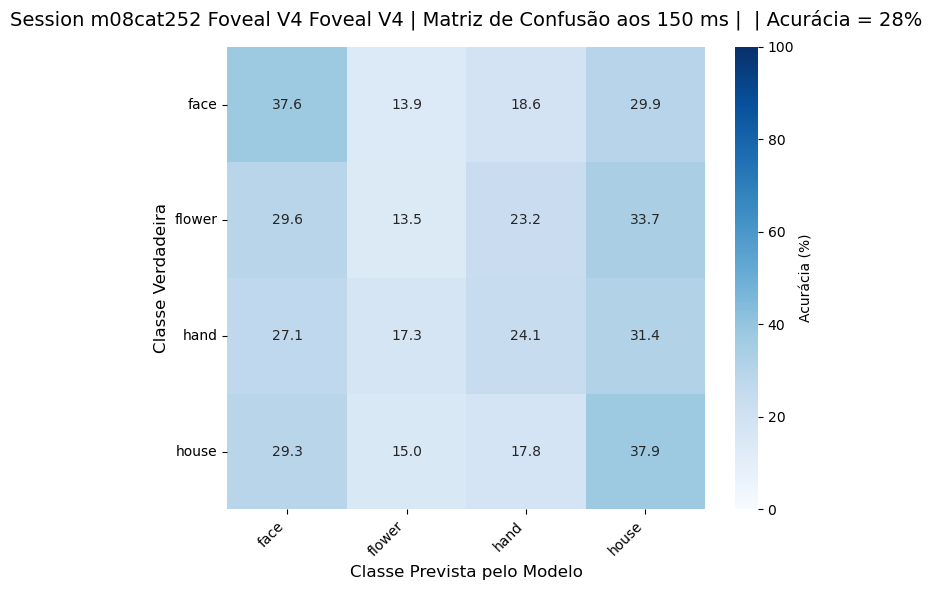

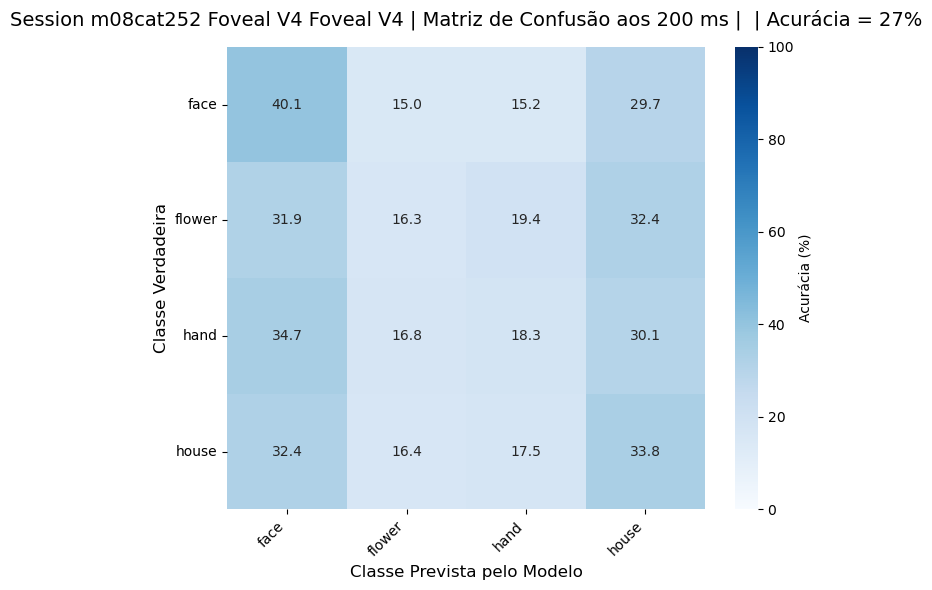

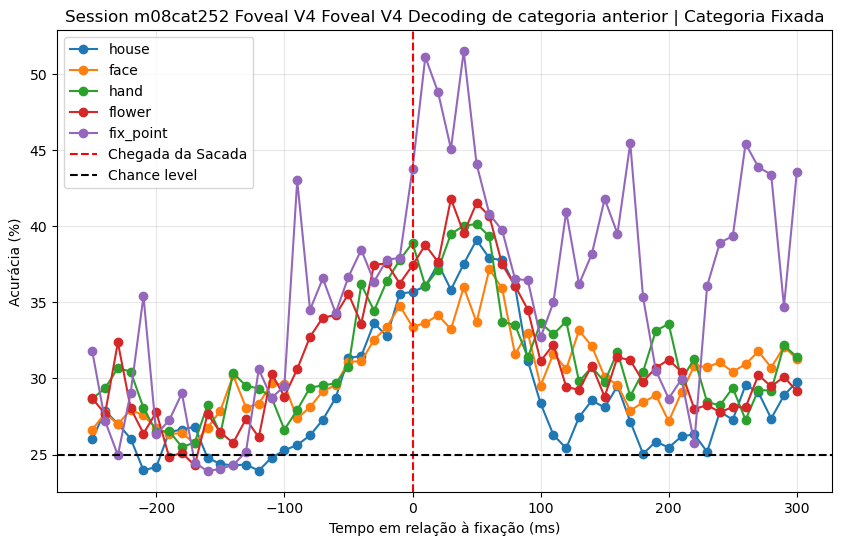

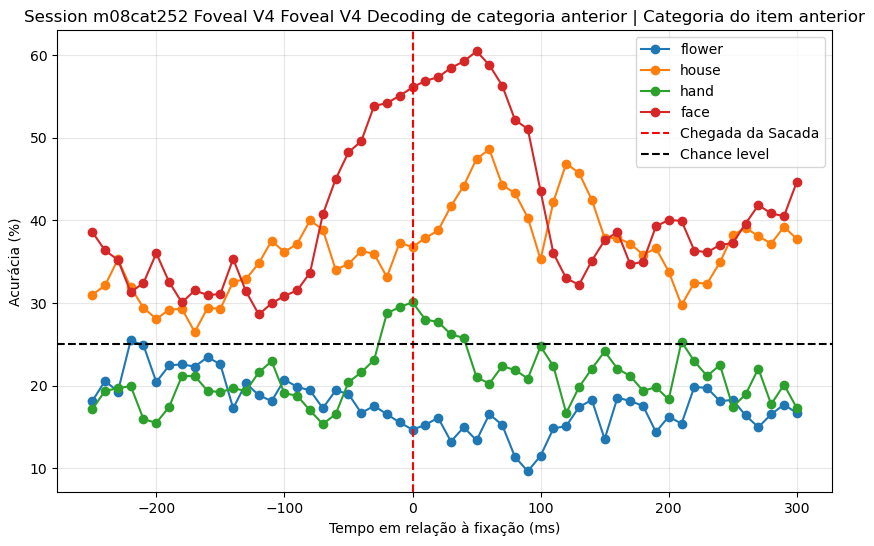

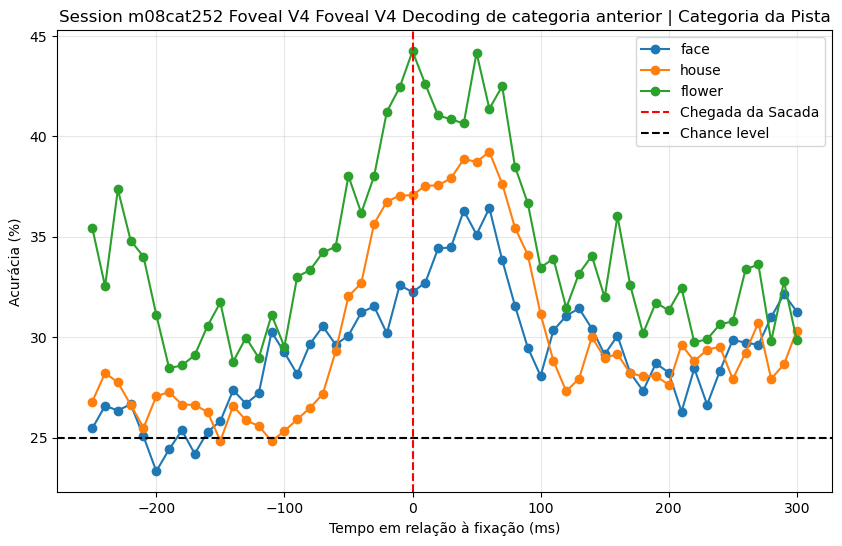

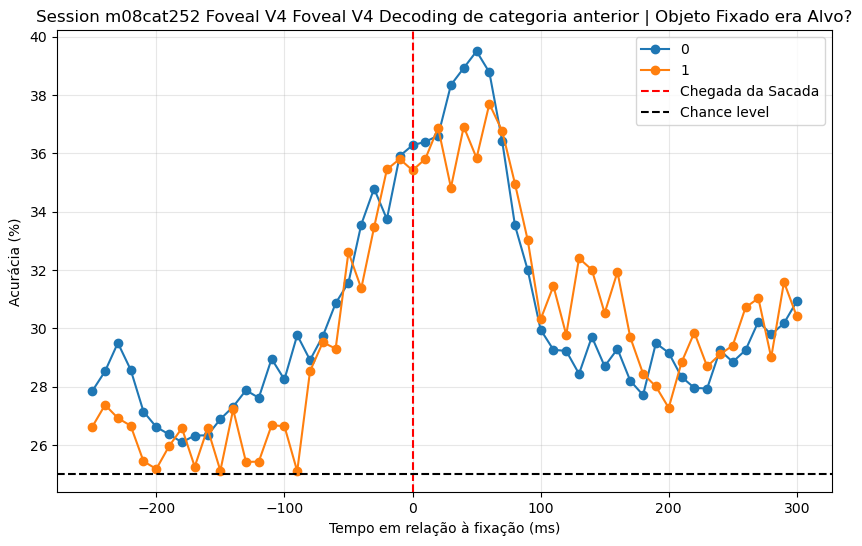

In [29]:
plot_decoding(res_prevcat)

plot_multiple_CM(res_prevcat,[-100,-50,0,50,100,150,200])


txt_add_title = 'Decoding de categoria anterior'

classes_plotar = res_prevcat['mean_acc_cat_atual'].keys()
titulo_plot = 'Categoria Fixada'
plot_decoding_by_class(res_prevcat, 'mean_acc_cat_atual', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_prevcat['mean_acc_cat_anterior'].keys()
titulo_plot = 'Categoria do item anterior'
plot_decoding_by_class(res_prevcat, 'mean_acc_cat_anterior', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_prevcat['mean_acc_cat_cue'].keys()
titulo_plot = 'Categoria da Pista'
plot_decoding_by_class(res_prevcat, 'mean_acc_cat_cue', classes_plotar, titulo_plot, txt_add_title)

classes_plotar = res_prevcat['mean_acc_is_cue'].keys()
titulo_plot = 'Objeto Fixado era Alvo?'
plot_decoding_by_class(res_prevcat, 'mean_acc_is_cue', classes_plotar, titulo_plot, txt_add_title)